# 04. Huấn luyện, Tối ưu & Đánh giá Local Outlier Factor (LOF)

---

## PHẦN A: TỔNG QUAN GIAI ĐOẠN 4 (PHASE 4 OVERVIEW)

### 1. Mục tiêu Giai đoạn 4 (Phase 4 Objectives)
* **Môn học:** Khai phá Dữ liệu (Data Mining) — Học kỳ 1, Năm 2026 — Học viện Công nghệ Bưu chính Viễn thông (PTIT).
* **Nhóm sinh viên thực hiện:**
  * **Nguyễn Minh Hoàng (B23DCVT173)** — *Modeling & Evaluation Lead*
  * **Nguyễn Văn Hiển Vinh (B23DCVT461)** — *Data & Preprocessing Lead*
* **Mục tiêu kỹ thuật cốt lõi:**
  1. Tái lập chiến lược lấy mẫu ngẫu nhiên không hoàn lại $N_{\text{LOF}} = 25,000$ giao dịch từ tập `Train_Normal` (`RANDOM_STATE = 42`) và đóng gói chỉ số mẫu `data/processed/train_indices_lof.npy`.
  2. Xây dựng mô hình **Baseline LOF** (`n_neighbors=20`, `novelty=True`, `metric="minkowski"`, `p=2`, `contamination="auto"`) thông qua module dùng chung `src/models.py`.
  3. Thực hiện **Coarse Grid Search** với `n_neighbors ∈ [10, 20, 30, 50]` (tái sử dụng kết quả `k=20` từ Baseline, không fit lại thừa) và chọn cấu hình tốt nhất dựa trên chỉ số **Average Precision (AP)** trên tập Validation ($42,721$ mẫu).
  4. Thực hiện **Threshold Moving** trên đường cong Precision-Recall để chọn ngưỡng quyết định $\tau^*_{\text{LOF}}$ tối ưu $F_1$-score trên tập Validation; trực quan hóa phân phối điểm số và PR-Curve (300 DPI).
  5. Tiến hành **Duplicate Sensitivity Analysis (Check A & Check B)** để định lượng tác động của các bản ghi Normal trùng lặp giữa Train và Validation mà không huấn luyện lại mô hình hay thay đổi ngưỡng $\tau^*_{\text{LOF}}$.
  6. Đo đạc chi phí tài nguyên (**Runtime** bằng `time.perf_counter()`, **OS RAM** bằng `psutil`, **Python heap** bằng `tracemalloc`) và đóng gói đầy đủ artifacts tái lập được $100\%$.

### 2. Vai trò của LOF trong Kiến trúc Dự án
* **LOF là Mô hình Cốt lõi Thứ 2 (Model 2)** trong bộ ba thuật toán đối chuẩn Unsupervised / Novelty Detection (`Isolation Forest`, `Local Outlier Factor`, `One-Class SVM`).
* Sau Phase 4, mô hình và kết quả Validation của LOF sẽ được bàn giao sang Phase 6 (so sánh tổng hợp 3 mô hình & phân tích Ma trận chi phí kinh tế) trước khi mở niêm phong tập Test duy nhất một lần ở Phase 8.

### 3. Đầu vào (Inputs) & Đầu ra (Outputs)
* **Đầu vào (từ Phase 2):** `data/processed/creditcard_preprocessed.npz` — chỉ nạp `X_train`, `y_train`, `X_val`, `y_val`, `feature_names` ($30$ đặc trưng: `V1..V28`, `scaled_amount`, `scaled_time`).
* **Đầu ra (8 artifacts bàn giao Phase 4):**
  1. `notebooks/04_local_outlier_factor.ipynb` — Notebook hoàn chỉnh, tái lập khi chạy Restart & Run All.
  2. `data/processed/train_indices_lof.npy` — Mảng chỉ số $25,000$ mẫu huấn luyện LOF.
  3. `models/lof_best.joblib` — Mô hình LOF tối ưu đã tuần tự hóa.
  4. `reports/phase4_lof_results.csv` — Bảng kết quả Grid Search kèm runtime và quan sát bộ nhớ.
  5. `reports/phase4_lof_metadata.json` — Metadata thực nghiệm chi tiết.
  6. `reports/phase4_lof_summary.md` — Báo cáo tóm tắt Phase 4.
  7. `reports/figures/08_lof_score_distribution.png` — Phân phối Anomaly Score giữa Normal và Fraud kèm $\tau^*_{\text{LOF}}$.
  8. `reports/figures/09_lof_pr_curve.png` — Đường cong Precision-Recall Curve của Baseline và Best LOF.

### 4. Khác biệt Cốt lõi giữa LOF và Isolation Forest (Phase 3)
| Tiêu chí so sánh | Isolation Forest (Phase 3) | Local Outlier Factor (Phase 4) |
| :--- | :--- | :--- |
| **Cơ chế phát hiện dị biệt** | **Toàn cục dựa trên cây (Tree-based Isolation):** Cô lập điểm thưa bằng các nhát cắt ngẫu nhiên song song trục tọa độ. | **Cục bộ dựa trên mật độ láng giềng ($k$-NN Density Ratio):** So sánh mật độ tại điểm xét với mật độ trung bình quanh $k$ láng giềng gần nhất. |
| **Kích thước tập huấn luyện** | Chạy tuyến tính trên toàn bộ $199,020$ mẫu `Train_Normal`. | Lấy mẫu có kiểm soát $N_{\text{LOF}} = 25,000$ mẫu để kiểm soát tài nguyên RAM/thời gian khi tìm $k$-NN trong $30$ chiều. |
| **Độ nhạy với thang đo đặc trưng** | Bất biến với phép co giãn đơn điệu trên từng trục riêng lẻ. | **Phụ thuộc trực tiếp vào khoảng cách Euclidean ($p=2$)**, nên chuẩn hóa `RobustScaler` cho `Amount`, `Time` là bắt buộc. |
| **Khả năng xử lý đa cụm mật độ** | Kém nhạy hơn khi điểm dị biệt nằm sát cụm lớn nhưng thưa cục bộ (Local Anomaly). | Bắt rất tốt các **dị biệt cục bộ** nằm lệch khỏi cụm địa phương dù khoảng cách tuyệt đối tới tâm toàn cục không quá lớn. |

> **[NGUYÊN TẮC BẢO MẬT TẬP TEST & KIỂM SOÁT RÒ RỈ]:** Tập Test (`X_test`, `y_test`) **TUYỆT ĐỐI KHÔNG ĐƯỢC NẠP VÀO BỘ NHỚ** ở bất kỳ cell nào của Phase 4. Đồng thời, nhóm không tuyên bố *Zero Leakage tuyệt đối* vì dữ liệu gốc Kaggle chứa các giao dịch trùng lặp tự nhiên gây cross-split overlap giữa Train và Validation — vấn đề này sẽ được đo lường tường minh tại bước Duplicate Sensitivity Analysis.

---

## PHẦN B: CƠ SỞ TOÁN HỌC & NGUYÊN LÝ THUẬT TOÁN LOF (ALGORITHM EXPLANATION)

### 1. Trực giác Hình học: Vì sao gọi là "Dị biệt Cục bộ"?
Trong bài toán thực tế, hành vi tiêu dùng hợp pháp có nhiều cụm khác nhau (ví dụ: cụm thanh toán siêu thị nhỏ dày đặc vs cụm đặt vé máy bay thưa hơn). Một thuật toán chỉ đo khoảng cách toàn cục dễ gán nhầm giao dịch hợp lệ ở rìa cụm thưa thành gian lận, hoặc bỏ sót kẻ gian lẩn khuất gần sát biên một cụm siêu đặc.

**Local Outlier Factor (Breunig, Kriegel, Ng, Sander — ACM SIGMOD 2000)** giải quyết điều này bằng ý tưởng rất tự nhiên:
* Một điểm được xem là **bình thường** nếu độ đông đúc xung quanh nó **tương đương** độ đông đúc xung quanh các hàng xóm gần nhất của nó ($\text{LOF} \approx 1$).
* Một điểm bị coi là **dị biệt cục bộ** nếu xung quanh nó **thưa thớt hơn hẳn** so với hàng xóm của nó ($\text{LOF} \gg 1$).

---

### 2. Bốn Bước Tính Toán Toán học Từ Cơ bản Đến Công thức LOF

#### Bước 1: Khoảng cách Euclid trong $30$ chiều & Tập $k$-Láng giềng ($N_k(p)$)
Giả sử tập tham chiếu `X_train_lof` gồm $N = 25,000$ điểm trong không gian $d = 30$ chiều. Với hai giao dịch $p, o \in \mathbb{R}^{30}$, khoảng cách Minkowski bậc $p=2$ chính là khoảng cách Euclid quen thuộc:
$$d(p, o) = \sqrt{\sum_{j=1}^{30} (p_j - o_j)^2}$$
* **$k$-distance($o$):** Là khoảng cách từ điểm $o$ đến người láng giềng thứ $k$ gần nhất trong tập tham chiếu (bán kính chứa ít nhất $k$ điểm khác $o$).
* **$N_k(p)$:** Tập hợp $k$ láng giềng gần nhất của điểm cần chấm $p$ trong tập tham chiếu `X_train_lof`.

#### Bước 2: Reachability Distance (Khoảng cách có thể tiếp cận)
Khoảng cách tiếp cận bậc $k$ từ điểm $p$ tới láng giềng $o$ được định nghĩa là:
$$\text{reach-dist}_k(p, o) = \max\bigl\{ k\text{-distance}(o),\; d(p, o) \bigr\}$$
* **Ý nghĩa trực giác:**
  * Nếu $p$ ở xa $o$ (nằm ngoài vùng $k$ láng giềng của $o$), $\text{reach-dist}_k(p, o) = d(p, o)$ — lấy khoảng cách thật.
  * Nếu $p$ nằm lọt thỏm sát cạnh hoặc **trùng khít** với $o$ ($d(p, o) = 0$), phép $\max$ tự động thay thế khoảng cách bằng một "sàn tối thiểu" là $k\text{-distance}(o)$. Nhờ vậy công thức **làm mượt dao động thống kê cục bộ** và **tránh phép chia cho $0$** khi xuất hiện bản ghi trùng lặp!

#### Bước 3: Local Reachability Density ($\text{lrd}_k$) — Mật độ Tiếp cận Cục bộ
Mật độ cục bộ tại điểm $p$ là nghịch đảo của khoảng cách tiếp cận trung bình từ $p$ tới $k$ hàng xóm gần nhất của nó:
$$\text{lrd}_k(p) = \left( \frac{\sum_{o \in N_k(p)} \text{reach-dist}_k(p, o)}{|N_k(p)|} \right)^{-1}$$
* Hàng xóm ở càng gần $\implies$ mẫu số càng nhỏ $\implies$ mật độ $\text{lrd}_k(p)$ càng cao (vùng đông đúc).
* Hàng xóm ở rất xa $\implies$ mẫu số lớn $\implies$ mật độ $\text{lrd}_k(p)$ rất thấp (vùng cô lập thưa thớt).

#### Bước 4: Công thức Điểm Số LOF ($\text{LOF}_k(p)$)
Hệ số dị biệt cục bộ của điểm $p$ là trung bình cộng tỷ số giữa mật độ của $k$ hàng xóm so với mật độ của chính $p$:
$$\text{LOF}_k(p) = \frac{1}{|N_k(p)|} \sum_{o \in N_k(p)} \frac{\text{lrd}_k(o)}{\text{lrd}_k(p)}$$
* **Biện luận giá trị $\text{LOF}_k(p)$:**
  * $\text{LOF}_k(p) \approx 1$: Mật độ tại $p$ ngang bằng mật độ các hàng xóm $\implies$ **Giao dịch bình thường**.
  * $\text{LOF}_k(p) < 1$: Điểm $p$ nằm trong vùng dày đặc hơn cả vùng biên lân cận $\implies$ **Giao dịch rất an toàn**.
  * $\text{LOF}_k(p) \gg 1$: Mật độ tại $p$ thấp hơn nhiều lần so với hàng xóm (tử số lớn, mẫu số nhỏ) $\implies$ **Ứng viên dị biệt cục bộ cao**.

---

### 3. Vai trò Tham số, Lời nguyền Số chiều & Quy chuẩn API Scikit-learn

| Thành phần / Khái niệm | Giải thích kỹ thuật & Lý do thiết lập trong Phase 4 |
| :--- | :--- |
| **`n_neighbors` ($k$)** | Số lượng láng giềng dùng ước lượng mật độ. Nếu $k$ quá nhỏ (vd $k=10$), mật độ dễ nhiễu bởi biến động ngẫu nhiên; nếu $k$ quá lớn (vd $k=50$), ranh giới bị làm mượt quá mức có thể hòa tan các cụm gian lận nhỏ. Vì vậy nhóm khảo sát thô `[10, 20, 30, 50]`. |
| **`novelty=True` (BẮT BUỘC)** | Mặc định `novelty=False` chỉ chấm điểm nội bộ các điểm có sẵn trong tập fit (`negative_outlier_factor_`) và **không có** hàm `.score_samples(X_val)`. Bắt buộc bật `novelty=True` để giữ tập tham chiếu `Train_Normal` đứng yên và chấm điểm hoàn toàn độc lập các giao dịch mới trên tập Validation. Không dùng `negative_outlier_factor_` để đánh giá Validation. |
| **Đảo dấu `score_samples(X)`** | Trong `scikit-learn`, `LOF.score_samples(X)` trả về giá trị **âm** (xấp xỉ $-\text{LOF}_k(x)$): điểm càng bất thường thì giá trị càng âm sâu. Do đó `src.models.compute_unified_anomaly_scores()` thực hiện đảo dấu $S(x) = -\text{score\_samples}(x) = +\text{LOF}_k(x)$ để tuân thủ quy ước toàn dự án: **Điểm càng cao $\implies$ Nguy cơ dị biệt càng lớn**. |
| **`contamination="auto"`** | Tương tự Isolation Forest, `contamination` trong scikit-learn chỉ dịch ngưỡng cắt nội bộ `offset_` của hàm `.predict()`, hoàn toàn **không đổi** kết quả `.score_samples()` và không ảnh hưởng tới Average Precision (AP). Nhóm giữ `contamination="auto"` và tách riêng bước tối ưu ngưỡng $\tau^*_{\text{LOF}}$ trên Validation. |
| **Curse of Dimensionality (30D)** | Trong không gian $d=30$ chiều, khoảng cách giữa cặp điểm gần nhất và xa nhất có xu hướng tiệm cận nhau khiến các cấu trúc cây không gian (`kd_tree`, `ball_tree`) mất hiệu lực chia nhánh. Với `algorithm="auto"`, `scikit-learn` thường chuyển về tìm kiếm chính xác `brute` tận dụng nhân ma trận BLAS song song. |
| **Tầm quan trọng của Scaling** | Vì `metric="minkowski", p=2` (Euclidean) cộng bình phương sai khác của cả 30 chiều, nếu không có `RobustScaler` ở Phase 2, biên độ lớn của `Amount` (tối đa $25,691$ USD) và `Time` (tối đa $172,792$ giây) sẽ chi phối hoàn toàn khoảng cách và làm lu mờ 28 biến PCA `V1–V28`. |

> **[CẢNH BÁO DIỄN GIẢI HỌC THUẬT]:**  
> 1. Điểm số $S_{\text{LOF}}(x)$ là tỷ số mật độ cục bộ tương đối (thường $\ge 0.9$, không bị chặn trên), **KHÔNG PHẢI xác suất gian lận đã hiệu chuẩn** (ví dụ $S = 3.16$ không mang nghĩa "316% xác suất gian lận").  
> 2. **Outlier $\neq$ Fraud:** Một giao dịch hợp lệ có giá trị mua sắm lạ vẫn có thể có mật độ thưa và bị gán điểm cao (False Positive). Vì vậy bước chọn ngưỡng trên Validation và tích hợp Ma trận chi phí ở Phase 6 là không thể thiếu.

### 4. Ưu điểm & Nhược điểm của LOF
* **Ưu điểm:**
  * Phát hiện xuất sắc các bất thường cục bộ (Local Anomalies) trong dữ liệu đa cụm có mật độ khác nhau — điểm yếu của các mô hình toàn cục thuần túy.
  * Không giả định trước dạng phân phối tham số toàn cục (như phân phối chuẩn nhiều chiều).
* **Nhược điểm:**
  * Chi phí tính toán & bộ nhớ cao ($O(N^2 \cdot d)$ khi tìm láng giềng toàn cục), bắt buộc phải lấy mẫu con ($N = 25,000$) trên máy cá nhân.
  * Chi phí suy luận (scoring latency) trên từng giao dịch mới chậm hơn đáng kể so với cây cô lập iForest vì phải đo khoảng cách tới $25,000$ mẫu tham chiếu.
  * Khó chọn ngưỡng trực tiếp nếu không có tập Validation để đối chuẩn.

---

## PHẦN C: TRIỂN KHAI & LUỒNG DỮ LIỆU (IMPLEMENTATION & DATA FLOW)

### Bước 1: Thiết lập Môi trường, Tái sử dụng Module `src/` & Hàm Hỗ trợ Chuẩn
* **Mục đích:** Khởi tạo đường dẫn gốc an toàn (hoạt động đúng cả khi chạy từ `notebooks/` lẫn thư mục gốc repo), tái sử dụng cấu hình (`src.config`), bộ khởi tạo mô hình (`src.models`) và công cụ đánh giá (`src.metrics`), đồng thời xây dựng các hàm hỗ trợ ngắn gọn (Single Responsibility) cho đo bộ nhớ, chấm điểm theo batch và tìm ngưỡng $F_1$.
* **Input:** Các module chuẩn trong `src/`, thư viện khoa học (`numpy`, `pandas`, `scikit-learn`, `psutil`, `matplotlib`, `seaborn`).
* **Logic:** Tránh lặp lại code giữa EXP 4.0 và EXP 4.1; tách riêng đo Python heap (`tracemalloc`) với bộ nhớ tiến trình OS (`psutil`: RSS và Peak Working Set); chia phép tính $F_1$ bằng `np.divide(..., where=denom > 0)` để triệt tiêu cảnh báo chia cho `0`.
* **Output:** Môi trường đồ họa sẵn sàng, thư mục `models/`, `reports/`, `reports/figures/` và các hàm helper đã được nạp.
* **Lý do lựa chọn:** Tuân thủ Clean Code / DRY, không sửa đổi `src/models.py` vì `build_local_outlier_factor` và `compute_unified_anomaly_scores` đã đáp ứng đầy đủ cấu hình đã duyệt.
* **Rủi ro nếu làm sai:** Nếu dùng `sys.path.append(str(Path.cwd().parent))` cứng như stub cũ thì sẽ lỗi `ModuleNotFoundError` khi chạy từ thư mục gốc; nếu dùng `tracemalloc` thay cho RAM hệ điều hành sẽ đánh giá sai bộ nhớ native C/BLAS của scikit-learn.

In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG, MODULE SRC/ & HÀM HỖ TRỢ ĐO LƯỜNG CHUẨN
# ==============================================================================
import json
import os
import sys
import time
import tracemalloc
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn

# Thiết lập ROOT_DIR an toàn bất kể notebook được chạy từ thư mục gốc hay notebooks/
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import (
    FIGURES_DIR,
    LOF_SAMPLE_SIZE,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
)
from src.metrics import compute_auprc, evaluate_threshold
from src.models import build_local_outlier_factor, compute_unified_anomaly_scores

MODELS_DIR = ROOT_DIR / "models"
REPORTS_DIR = ROOT_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Ngưỡng cảnh báo tài nguyên và kích thước batch chấm điểm Validation
BATCH_SIZE = 5000
MAX_CONFIG_SECONDS = 600.0
PROCESS = psutil.Process(os.getpid())

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"


def get_process_rss_mb(process: psutil.Process = PROCESS) -> float:
    """
    Đo bộ nhớ Resident Set Size (RSS) hiện thời của tiến trình Python tính bằng MB.

    Input: process (psutil.Process) — đối tượng tiến trình đang chạy.
    Output: float — dung lượng RSS hiện tại (MB).
    Giả định: Phản ánh bộ nhớ thực tế cấp hệ điều hành, bao gồm cả mảng native C/BLAS.
    """
    return float(process.memory_info().rss / (1024.0 * 1024.0))


def get_process_peak_wset_mb(process: psutil.Process = PROCESS) -> float | None:
    """
    Trích xuất Peak Working Set (đỉnh bộ nhớ tiến trình Windows) nếu hệ điều hành hỗ trợ.

    Input: process (psutil.Process).
    Output: float | None — giá trị peak_wset (MB) trên Windows, hoặc None nếu không khả dụng.
    """
    mem_info = process.memory_info()
    peak_wset = getattr(mem_info, "peak_wset", None)
    return float(peak_wset / (1024.0 * 1024.0)) if peak_wset is not None else None


def score_in_batches(
    model,
    X: np.ndarray,
    batch_size: int = BATCH_SIZE,
    model_name: str = "LOF",
) -> np.ndarray:
    """
    Chấm điểm dị biệt thống nhất theo từng batch nhằm kiểm soát đỉnh RAM suy luận.

    Input: model đã fit, ma trận đặc trưng X (ndarray), batch_size (int), model_name (str).
    Output: np.ndarray 1D kiểu float64 chứa điểm S = -score_samples(X) (cao -> dị biệt).
    Rủi ro nếu làm sai: Không đảo dấu hoặc thay đổi chiều điểm số sẽ làm sai lệch hoàn toàn AP.
    """
    # Vì LOF novelty=True chấm từng điểm mới độc lập so với tập tham chiếu 25,000 mẫu,
    # chia batch không làm thay đổi kết quả toán học mà giúp kiểm soát bộ nhớ đệm khoảng cách.
    # Đảo dấu (-score_samples) trong compute_unified_anomaly_scores để điểm cao = bất thường cao,
    # tương thích với average_precision_score (chỉ số ranking toàn dải tốt nhất khi Fraud = 0.1732%).
    batches = [
        compute_unified_anomaly_scores(
            model, X[start:start + batch_size], model_name=model_name
        )
        for start in range(0, len(X), batch_size)
    ]
    scores = np.concatenate(batches).astype(np.float64, copy=False)
    assert len(scores) == len(X), f"Số điểm dự báo không khớp: {len(scores)} != {len(X)}"
    assert np.all(np.isfinite(scores)), "[LỖI] Điểm LOF chứa giá trị NaN hoặc Inf!"
    return scores


def compute_f1_optimal_threshold(y_true: np.ndarray, scores: np.ndarray) -> dict:
    """
    Tìm ngưỡng tối ưu F1-score trên tập Validation từ đường cong Precision-Recall Curve.

    Input: y_true (nhãn 0/1), scores (Anomaly Score liên tục cùng chiều: cao -> dị biệt).
    Output: dict chứa ap_score, precisions, recalls, thresholds và eval_metrics tại tau*.
    Rủi ro nếu làm sai: Lệch chỉ số giữa precision/recall (dài hơn thresholds 1 phần tử)
    hoặc chia cho 0 khi P + R = 0.
    """
    ap_score, precisions, recalls, thresholds = compute_auprc(y_true, scores)
    assert len(thresholds) == len(precisions) - 1 == len(recalls) - 1

    # precision_recall_curve thêm 1 điểm neo cuối (P=1, R=0) không gắn với threshold nào
    p_valid = precisions[:-1]
    r_valid = recalls[:-1]
    denom = p_valid + r_valid

    # Xử lý an toàn trường hợp P + R = 0 để tránh RuntimeWarning
    f1_curve = np.divide(
        2.0 * p_valid * r_valid,
        denom,
        out=np.zeros_like(denom, dtype=np.float64),
        where=denom > 0,
    )
    best_idx = int(np.argmax(f1_curve))
    optimal_threshold = float(thresholds[best_idx])

    eval_metrics = evaluate_threshold(y_true, scores, optimal_threshold)
    total_cm = (
        eval_metrics["TP"] + eval_metrics["FP"] + eval_metrics["TN"] + eval_metrics["FN"]
    )
    assert total_cm == len(y_true), "[LỖI] Tổng Confusion Matrix không khớp kích thước mẫu!"
    assert np.isclose(eval_metrics["f1"], float(f1_curve[best_idx]), atol=1e-9), (
        f"[LỖI] F1 ({eval_metrics['f1']}) không khớp PR curve ({f1_curve[best_idx]})!"
    )

    return {
        "ap": float(ap_score),
        "precisions": precisions,
        "recalls": recalls,
        "thresholds": thresholds,
        "eval_metrics": eval_metrics,
    }


def evaluate_lof_config(
    n_neighbors: int,
    X_train_sub: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    batch_size: int = BATCH_SIZE,
) -> dict:
    """
    Huấn luyện và đánh giá một cấu hình Local Outlier Factor (novelty=True) trên Validation.

    Input: n_neighbors (int), X_train_sub (25k x 30), X_val (42,721 x 30), y_val (42,721).
    Output: dict chứa model đã fit, vector điểm Validation và hồ sơ đo lường đầy đủ.
    Giả định: Dùng cấu hình Euclidean (metric='minkowski', p=2), contamination='auto'.
    """
    assert 1 <= n_neighbors < len(X_train_sub), (
        f"n_neighbors={n_neighbors} không hợp lệ với kích thước mẫu {len(X_train_sub)}"
    )

    # Bật novelty=True vì cần giữ cố định tập tham chiếu Train_Normal và chấm điểm độc lập
    # cho giao dịch mới (X_val); metric Euclidean (p=2) phù hợp với 30 chiều đã RobustScale.
    model = build_local_outlier_factor(n_neighbors=n_neighbors, novelty=True)
    assert model.novelty is True, "[LỖI KHOA HỌC] novelty bắt buộc phải bằng True!"
    assert model.metric == "minkowski" and model.p == 2, (
        f"[LỖI CẤU HÌNH] Kỳ vọng metric='minkowski', p=2; thực tế: {model.metric}, p={model.p}"
    )
    assert model.contamination == "auto", (
        f"[LỖI CẤU HÌNH] Kỳ vọng contamination='auto', thực tế: {model.contamination}"
    )

    rss_before = get_process_rss_mb()
    if tracemalloc.is_tracing():
        tracemalloc.stop()
    tracemalloc.start()
    try:
        t_fit_start = time.perf_counter()
        model.fit(X_train_sub)
        fit_time = time.perf_counter() - t_fit_start
        rss_after_fit = get_process_rss_mb()

        t_score_start = time.perf_counter()
        val_scores = score_in_batches(
            model, X_val, batch_size=batch_size, model_name="LOF"
        )
        score_time = time.perf_counter() - t_score_start

        rss_after_score = get_process_rss_mb()
        _, heap_peak_bytes = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()

    threshold_info = compute_f1_optimal_threshold(y_val, val_scores)
    eval_m = threshold_info["eval_metrics"]
    total_time = fit_time + score_time

    return {
        "model": model,
        "scores": val_scores,
        "threshold_info": threshold_info,
        "summary": {
            "n_neighbors": int(n_neighbors),
            "sample_size": int(len(X_train_sub)),
            "novelty": bool(model.novelty),
            "metric": str(model.metric),
            "p": int(model.p),
            "contamination": str(model.contamination),
            "effective_metric": str(model.effective_metric_),
            "fit_method": str(model._fit_method),
            "fit_time_sec": float(fit_time),
            "score_time_sec": float(score_time),
            "total_time_sec": float(total_time),
            "rss_before_mb": float(rss_before),
            "rss_after_fit_mb": float(rss_after_fit),
            "rss_after_score_mb": float(rss_after_score),
            "rss_delta_mb": float(rss_after_score - rss_before),
            "tracemalloc_peak_mb": float(heap_peak_bytes / (1024.0 * 1024.0)),
            "peak_wset_mb": get_process_peak_wset_mb(),
            "val_ap": float(threshold_info["ap"]),
            "optimal_threshold": float(eval_m["threshold"]),
            "val_precision": float(eval_m["precision"]),
            "val_recall": float(eval_m["recall"]),
            "val_f1": float(eval_m["f1"]),
            "tp": int(eval_m["TP"]),
            "fp": int(eval_m["FP"]),
            "tn": int(eval_m["TN"]),
            "fn": int(eval_m["FN"]),
            "status": (
                "WARNING_EXCEEDED_10MIN"
                if total_time > MAX_CONFIG_SECONDS
                else "COMPLETED"
            ),
        },
    }


print("=" * 74)
print(f"-> Khởi tạo môi trường Phase 4 thành công (RANDOM_STATE = {RANDOM_STATE})")
print(
    f"-> Python {sys.version.split()[0]} | NumPy {np.__version__} | "
    f"Pandas {pd.__version__} | scikit-learn {sklearn.__version__}"
)
print(
    f"-> Process RSS ban đầu: {get_process_rss_mb():.2f} MB | "
    f"LOF_SAMPLE_SIZE = {LOF_SAMPLE_SIZE:,}"
)
print("=" * 74)

-> Khởi tạo môi trường Phase 4 thành công (RANDOM_STATE = 42)
-> Python 3.12.10 | NumPy 2.5.4 | Pandas 3.1.0 | scikit-learn 1.9.1
-> Process RSS ban đầu: 191.43 MB | LOF_SAMPLE_SIZE = 25,000


### Bước 2: Nạp Dữ liệu Tiền xử lý từ Phase 2 & Kiểm tra Toàn vẹn (Strict Zero-Test-Access)
* **Mục đích:** Nạp đúng 4 mảng cần thiết (`X_train`, `y_train`, `X_val`, `y_val`) và `feature_names` từ `data/processed/creditcard_preprocessed.npz` mà không nạp hay đọc tập Test.
* **Input:** File nén `data/processed/creditcard_preprocessed.npz` do Phase 2 xuất ra.
* **Logic:** Mở context manager `np.load(...)`, chỉ trích xuất khóa Train và Validation; thực thi các câu lệnh `assert` kiểm tra shape, dtype `float64`, đúng $0$ ca Fraud trong `Train_Normal`, đúng $74$ ca Fraud trong `Validation`, đúng thứ tự $30$ đặc trưng `V1..V28, scaled_amount, scaled_time`, và $0$ giá trị NaN/Inf.
* **Output:** Các mảng `X_train`, `y_train`, `X_val`, `y_val` sạch trong RAM kèm danh sách `feature_names`.
* **Lý do lựa chọn:** Tái sử dụng hoàn toàn phân chia phân tầng và `RobustScaler` đã fit trên `Train_Normal` từ Phase 2, bảo đảm nhất quán dữ liệu tuyệt đối giữa Phase 3 (iForest) và Phase 4 (LOF).
* **Rủi ro nếu làm sai:** Nạp nhầm `X_test`/`y_test` sẽ vi phạm nguyên tắc niêm phong tập Test (Data Snooping); thay đổi thứ tự đặc trưng hoặc fit lại scaler sẽ làm hỏng toàn bộ kết quả so sánh liên mô hình ở Phase 6.

In [2]:
# ==============================================================================
# BƯỚC 2: NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ (CHỈ TRUY CẬP TRAIN_NORMAL & VALIDATION)
# ==============================================================================
npz_path = PROCESSED_DATA_DIR / "creditcard_preprocessed.npz"
assert npz_path.exists(), f"[LỖI] Không tìm thấy file dữ liệu tiền xử lý: {npz_path}"

# Chỉ fit LOF trên Train_Normal (0% Fraud) theo hướng tiếp cận Unsupervised/Novelty Detection;
# tuyệt đối không truy cập X_test/y_test trong Phase 4 để tránh Data Snooping trước Phase 8.
with np.load(npz_path, allow_pickle=True) as data:
    X_train = data["X_train"]
    y_train = data["y_train"]
    X_val = data["X_val"]
    y_val = data["y_val"]
    feature_names = list(data["feature_names"])

expected_features = [f"V{i}" for i in range(1, 29)] + ["scaled_amount", "scaled_time"]

assert X_train.shape == (199020, 30), f"Sai shape X_train: {X_train.shape}"
assert X_val.shape == (42721, 30), f"Sai shape X_val: {X_val.shape}"
assert X_train.dtype == np.float64 and X_val.dtype == np.float64, "Sai kiểu dữ liệu float64!"
assert int(y_train.sum()) == 0, f"[LỖI RÒ RỈ] Train chứa {y_train.sum()} Fraud!"
assert int(y_val.sum()) == 74, f"Số Fraud Validation không khớp 74: {y_val.sum()}"
assert feature_names == expected_features, "Thứ tự 30 đặc trưng bị thay đổi!"
assert np.isfinite(X_train).all() and np.isfinite(X_val).all(), "Phát hiện NaN/Inf trong dữ liệu!"
assert "X_test" not in locals() and "y_test" not in locals(), "[VI PHẠM] Đã nạp Test Set!"

print("=" * 74)
print("XÁC NHẬN TOÀN VẸN DỮ LIỆU ĐẦU VÀO PHASE 4:")
print(f"• X_train : {X_train.shape} | dtype={X_train.dtype} | Fraud={int(y_train.sum())} (100% Normal)")
print(f"• X_val   : {X_val.shape} | dtype={X_val.dtype} | Fraud={int(y_val.sum())} ({y_val.mean()*100:.4f}%)")
print(f"• Features: {len(feature_names)} cột ({feature_names[0]} .. {feature_names[-1]})")
print("• Test Set: [NIÊM PHONG TUYỆT ĐỐI] - Không đọc, không nạp vào bộ nhớ.")
print("=" * 74)

XÁC NHẬN TOÀN VẸN DỮ LIỆU ĐẦU VÀO PHASE 4:
• X_train : (199020, 30) | dtype=float64 | Fraud=0 (100% Normal)
• X_val   : (42721, 30) | dtype=float64 | Fraud=74 (0.1732%)
• Features: 30 cột (V1 .. scaled_time)
• Test Set: [NIÊM PHONG TUYỆT ĐỐI] - Không đọc, không nạp vào bộ nhớ.


### Bước 3: Lấy mẫu Kiểm soát $N_{\text{LOF}} = 25,000$ từ `Train_Normal` & Lưu `train_indices_lof.npy`
* **Mục đích:** Tạo và cố định tập mẫu con gồm $25,000$ giao dịch hợp lệ từ `Train_Normal` để huấn luyện mọi cấu hình LOF trên cùng một nền dữ liệu tham chiếu.
* **Input:** `X_train` ($199,020 \times 30$), `y_train` (toàn `0`), `RANDOM_STATE = 42`, `LOF_SAMPLE_SIZE = 25000`.
* **Logic:** Khởi tạo `np.random.RandomState(RANDOM_STATE)` và gọi `.choice(len(X_train), size=LOF_SAMPLE_SIZE, replace=False)` (sampling without replacement). Lưu mảng chỉ số ra `data/processed/train_indices_lof.npy`, nạp lại để xác thực tái lập bit-for-bit, rồi cắt `X_train_lof = X_train[train_indices_lof]`.
* **Output:** File `data/processed/train_indices_lof.npy` và ma trận `X_train_lof` kích thước $(25000, 30)$.
* **Lý do lựa chọn:** Trong không gian $30$ chiều, việc tính khoảng cách $k$-NN trên toàn bộ $199,020$ mẫu gây áp lực cực lớn về thời gian và bộ nhớ $O(N^2 \cdot d)$. Cố định $N = 25,000$ bảo đảm toàn bộ lưới Grid Search sử dụng đúng một tập mẫu đồng nhất và tái lập được 100% ở mọi máy.
* **Rủi ro nếu làm sai:**
  * Nếu quên `replace=False` hoặc không cố định seed, mỗi cấu hình $k$ sẽ học trên tập khác nhau khiến so sánh mất công bằng.
  * Cần phân biệt rạch ròi giữa **trùng index** (bị cấm, ở đây bằng `0`) với **trùng giá trị đặc trưng tự nhiên** trong Kaggle dataset (hai dòng khác index vẫn có thể chứa cùng vector giao dịch giống nhau — điều này hoàn toàn hợp lệ và được ghi nhận tường minh).

In [3]:
# ==============================================================================
# BƯỚC 3: LẤY MẪU KHÔNG HOÀN LẠI 25,000 MẪU NORMAL & LƯU CHỈ SỐ TÁI LẬP
# ==============================================================================
# Chọn LOF để bắt dị biệt mật độ cục bộ (bổ trợ cơ chế toàn cục của Isolation Forest).
# Lấy mẫu 25,000 từ Train_Normal bằng RandomState(42) vì k-NN 30D chạy brute-force O(N^2*d)
# sẽ quá tải nếu fit cả 199,020 dòng; lưu chỉ số đảm bảo mọi cấu hình so sánh công bằng.
rng = np.random.RandomState(RANDOM_STATE)
train_indices_lof = rng.choice(len(X_train), size=LOF_SAMPLE_SIZE, replace=False)

# Xác minh 5 tiêu chí sampling bắt buộc
assert len(train_indices_lof) == 25000, f"Số lượng index không đúng: {len(train_indices_lof)}"
assert len(np.unique(train_indices_lof)) == 25000, "[LỖI] Phát hiện index bị trùng lặp!"
assert train_indices_lof.min() >= 0 and train_indices_lof.max() < len(X_train), "Index vượt giới hạn Train!"
assert int(y_train[train_indices_lof].sum()) == 0, "[LỖI RÒ RỈ] Mẫu con chứa Fraud!"

# Kiểm chứng khả năng tái lập tức thì
rng_check = np.random.RandomState(RANDOM_STATE)
assert np.array_equal(
    train_indices_lof,
    rng_check.choice(len(X_train), size=LOF_SAMPLE_SIZE, replace=False),
), "[LỖI TÁI LẬP] Kết quả lấy mẫu không tái lập được!"

# Lưu chỉ số lấy mẫu và kiểm tra đọc lại từ đĩa
lof_indices_path = PROCESSED_DATA_DIR / "train_indices_lof.npy"
np.save(lof_indices_path, train_indices_lof)
reloaded_indices = np.load(lof_indices_path)
assert np.array_equal(train_indices_lof, reloaded_indices), "Lỗi khi đọc lại train_indices_lof.npy!"

X_train_lof = X_train[train_indices_lof]
assert X_train_lof.shape == (25000, 30), f"Sai shape X_train_lof: {X_train_lof.shape}"

# Phân biệt trùng index (0) với trùng vector đặc trưng nội bộ trong 25,000 mẫu
n_unique_feature_rows = len(np.unique(X_train_lof, axis=0))
n_internal_feature_dups = len(X_train_lof) - n_unique_feature_rows

print("=" * 74)
print("XÁC MINH LẤY MẪU TRAIN_NORMAL CHO LOF:")
print(f"• Đã lưu chỉ số mẫu      : {lof_indices_path} ({lof_indices_path.stat().st_size / 1024:.2f} KB)")
print(f"• Số lượng index         : {len(train_indices_lof):,} (Index duy nhất: {len(np.unique(train_indices_lof)):,})")
print(f"• Miền giá trị index     : [{int(train_indices_lof.min()):,}, {int(train_indices_lof.max()):,}] trong [0, {len(X_train)-1:,}]")
print(f"• Shape X_train_lof      : {X_train_lof.shape} ({X_train_lof.nbytes / (1024*1024):.2f} MB float64)")
print(f"• Số ca Fraud trong mẫu  : {int(y_train[train_indices_lof].sum())}")
print(f"• Dòng đặc trưng duy nhất: {n_unique_feature_rows:,} ({n_internal_feature_dups} bản ghi trùng đặc trưng nội bộ hợp lệ)")
print("=" * 74)

XÁC MINH LẤY MẪU TRAIN_NORMAL CHO LOF:
• Đã lưu chỉ số mẫu      : C:\Users\Vinh Nguyen\DATAMINING\data\processed\train_indices_lof.npy (97.78 KB)
• Số lượng index         : 25,000 (Index duy nhất: 25,000)
• Miền giá trị index     : [4, 199,019] trong [0, 199,019]
• Shape X_train_lof      : (25000, 30) (5.72 MB float64)
• Số ca Fraud trong mẫu  : 0
• Dòng đặc trưng duy nhất: 24,985 (15 bản ghi trùng đặc trưng nội bộ hợp lệ)


---

## PHẦN D: THỰC NGHIỆM & KẾT QUẢ (EXPERIMENTS & RESULTS)

### Bước 4 (EXP 4.0): Mô hình Baseline LOF (`n_neighbors=20`) & Kiểm thử Batch Consistency
* **Mục đích:** Thiết lập mốc đối chuẩn Baseline với cấu hình chuẩn `n_neighbors=20`, `novelty=True`, `metric="minkowski"`, `p=2`, `contamination="auto"` và kiểm chứng rằng việc chia batch `5,000` dòng chấm điểm trên Validation cho kết quả trùng khớp với chấm điểm nguyên khối.
* **Input:** `X_train_lof` ($25,000 \times 30$), `X_val` ($42,721 \times 30$), `y_val` ($42,721$, gồm $74$ Fraud).
* **Logic:** Gọi `evaluate_lof_config(n_neighbors=20, ...)` thông qua `src.models`; trích xuất điểm kiểm thử trên $500$ mẫu đầu bằng cả hai cách (nguyên khối và chia batch `5,000`) để `assert np.allclose`. Lưu giữ toàn bộ đối tượng `baseline_result` để tái sử dụng cho cấu hình `k=20` trong EXP 4.1.
* **Output:** Kết quả Baseline `Val AP`, `fit_time`, `score_time`, quan sát RAM (`RSS snapshot`, `RSS delta`, `tracemalloc peak`, `peak_wset`), `fit_method` và `effective_metric`.
* **Lý do lựa chọn:** Tách EXP 4.0 giúp minh bạch hóa giá trị tham chiếu trước khi tuning, đồng thời tiết kiệm thời gian tính toán ở bước Grid Search vì không phải fit lại `k=20`.
* **Rủi ro nếu làm sai:** Quên đảo dấu điểm số hoặc bật `novelty=False` sẽ khiến `score_samples` lỗi hoặc AP sụp đổ xuống $\approx 0$; nếu không kiểm tra batch consistency, có thể nghi ngờ cơ chế chia lô làm lệch metric.

In [4]:
# ==============================================================================
# BƯỚC 4 (EXP 4.0): BASELINE LOF (n_neighbors=20) & KIỂM THỬ BATCH SCORING
# ==============================================================================
baseline_result = evaluate_lof_config(
    n_neighbors=20,
    X_train_sub=X_train_lof,
    X_val=X_val,
    y_val=y_val,
    batch_size=BATCH_SIZE,
)
b_sum = baseline_result["summary"]

# Kiểm tra tính nhất quán giữa batch scoring (batch_size=5000) và scoring nguyên khối trên 500 mẫu
unbatched_sample_scores = compute_unified_anomaly_scores(
    baseline_result["model"], X_val[:500], model_name="LOF"
)
assert np.allclose(
    unbatched_sample_scores, baseline_result["scores"][:500], atol=1e-12, rtol=0.0
), "[LỖI] Batch scoring không khớp scoring nguyên khối!"

print("=" * 74)
print("KẾT QUẢ EXP 4.0 — BASELINE LOF (n_neighbors=20, novelty=True):")
print(f"• Fit method thực tế  : {b_sum['fit_method']} | Effective metric: {b_sum['effective_metric']}")
print("• Kiểm chứng Batch    : PASS (khớp nguyên khối tuyệt đối trên 500 mẫu đầu)")
print(f"• Fit time            : {b_sum['fit_time_sec']:.4f} giây")
print(f"• Validation Scoring  : {b_sum['score_time_sec']:.4f} giây (batch_size={BATCH_SIZE:,})")
print(f"• Baseline Val AP     : {b_sum['val_ap']:.6f} ({b_sum['val_ap']*100:.2f}%)")
print(
    f"• Optimal F1 tại tau* : {b_sum['val_f1']:.4f} "
    f"(P={b_sum['val_precision']:.4f}, R={b_sum['val_recall']:.4f}, tau*={b_sum['optimal_threshold']:.6f})"
)
print(
    f"• Bộ nhớ tiến trình   : RSS {b_sum['rss_before_mb']:.2f} -> {b_sum['rss_after_score_mb']:.2f} MB "
    f"(RSS delta: {b_sum['rss_delta_mb']:+.2f} MB | Python heap peak: {b_sum['tracemalloc_peak_mb']:.2f} MB)"
)
print("=" * 74)

KẾT QUẢ EXP 4.0 — BASELINE LOF (n_neighbors=20, novelty=True):
• Fit method thực tế  : brute | Effective metric: euclidean
• Kiểm chứng Batch    : PASS (khớp nguyên khối tuyệt đối trên 500 mẫu đầu)
• Fit time            : 3.7972 giây
• Validation Scoring  : 7.2257 giây (batch_size=5,000)
• Baseline Val AP     : 0.550848 (55.08%)
• Optimal F1 tại tau* : 0.6479 (P=0.6765, R=0.6216, tau*=3.124853)
• Bộ nhớ tiến trình   : RSS 257.37 -> 262.57 MB (RSS delta: +5.20 MB | Python heap peak: 16.56 MB)


### Bước 5 (EXP 4.1): Coarse Grid Search `n_neighbors ∈ [10, 20, 30, 50]` & Chọn Best LOF
* **Mục đích:** Khảo sát ảnh hưởng của kích thước lân cận cục bộ `n_neighbors ∈ [10, 20, 30, 50]` trên cùng tập `X_train_lof` ($25,000$ mẫu) và chọn ra mô hình LOF tối ưu theo **Validation AP**.
* **Input:** `X_train_lof`, `X_val`, `y_val`, kết quả `baseline_result` ($k=20$) từ EXP 4.0.
* **Logic:**
  * Giữ cố định `novelty=True`, `metric="minkowski"`, `p=2`, `contamination="auto"`, `BATCH_SIZE=5000`.
  * Nếu $k = 20$, tái sử dụng trực tiếp `baseline_result` (đánh dấu `COMPLETED_REUSED_BASELINE`), không fit lại thừa.
  * Với các giá trị $k$ còn lại (`10`, `30`, `50`), gọi `evaluate_lof_config(...)`, ghi nhận đủ runtime, RSS snapshot/delta, Python heap peak, `peak_wset`, `val_ap`. Theo dõi ngưỡng cảnh báo `10 phút` (`600s`).
  * Quy tắc chọn Best Model (Deterministic Selection Rule): Ưu tiên **`val_ap` cao nhất** $\to$ tie-break 1: **`total_time_sec` nhỏ hơn** $\to$ tie-break 2: **`n_neighbors` nhỏ hơn**.
* **Output:** Bảng `reports/phase4_lof_results.csv`, biến `best_lof_result`, `best_model`, `best_scores`, `best_eval`.
* **Lý do lựa chọn:** Giống triết lý của Phase 3, tập Validation chỉ có $74$ ca Fraud nên chọn **Coarse Grid Search** $4$ cấu hình kinh điển giúp giảm nguy cơ quá khớp lưới tham số vào tập Validation (Validation Overfitting).
* **Rủi ro nếu làm sai:** Chạy lại cấu hình trên hai sample size khác nhau rồi trộn bảng chọn model là sai phương pháp; đánh giá `best_model` bằng `F1` đơn điểm thay vì `AP` toàn dải sẽ phụ thuộc ngưỡng cục bộ.

In [5]:
# ==============================================================================
# BƯỚC 5 (EXP 4.1): COARSE GRID SEARCH n_neighbors = [10, 20, 30, 50]
# ==============================================================================
GRID_NEIGHBORS = [10, 20, 30, 50]
experiment_results = {}
grid_rows = []
runtime_limit_triggered = False

print("BẮT ĐẦU EXP 4.1 — COARSE GRID SEARCH LOF (N = 25,000 | Validation = 42,721)")
print("-" * 108)
print(
    f"{'ID':<4} | {'k':<4} | {'Fit(s)':<8} | {'Score(s)':<9} | "
    f"{'RSS Aft(MB)':<11} | {'HeapPeak(MB)':<12} | {'Val AP':<10} | {'Best F1':<8} | {'Trạng thái'}"
)
print("-" * 108)

for idx, k in enumerate(GRID_NEIGHBORS, start=1):
    if runtime_limit_triggered:
        # Không khởi chạy cấu hình mới nếu cấu hình trước vượt ngưỡng cảnh báo 10 phút
        grid_rows.append({
            "model_id": idx,
            "n_neighbors": k,
            "sample_size": len(X_train_lof),
            "novelty": True,
            "metric": "minkowski",
            "p": 2,
            "contamination": "auto",
            "status": "SKIPPED_AFTER_10MIN_WARNING",
        })
        continue

    if k == 20:
        # Tái sử dụng kết quả Baseline EXP 4.0, không fit lại thừa
        res = baseline_result
        status_label = "COMPLETED_REUSED_BASELINE"
    else:
        res = evaluate_lof_config(
            n_neighbors=k,
            X_train_sub=X_train_lof,
            X_val=X_val,
            y_val=y_val,
            batch_size=BATCH_SIZE,
        )
        status_label = res["summary"]["status"]

    row = dict(res["summary"])
    row["model_id"] = idx
    row["status"] = status_label
    if row["total_time_sec"] > MAX_CONFIG_SECONDS:
        runtime_limit_triggered = True

    experiment_results[k] = res
    grid_rows.append(row)

    print(
        f"#{idx:<3} | {k:<4} | {row['fit_time_sec']:<8.4f} | {row['score_time_sec']:<9.4f} | "
        f"{row['rss_after_score_mb']:<11.2f} | {row['tracemalloc_peak_mb']:<12.2f} | "
        f"{row['val_ap']:<10.6f} | {row['val_f1']:<8.4f} | {status_label}"
    )

print("-" * 108)

csv_cols_order = [
    "model_id", "n_neighbors", "sample_size", "novelty", "metric", "p",
    "contamination", "effective_metric", "fit_method", "fit_time_sec",
    "score_time_sec", "total_time_sec", "rss_before_mb", "rss_after_fit_mb",
    "rss_after_score_mb", "rss_delta_mb", "tracemalloc_peak_mb", "peak_wset_mb",
    "val_ap", "optimal_threshold", "val_precision", "val_recall", "val_f1",
    "tp", "fp", "tn", "fn", "status",
]
df_grid_results = pd.DataFrame(grid_rows)[csv_cols_order]
df_csv_export = df_grid_results.copy()
timing_mem_cols = [
    "fit_time_sec", "score_time_sec", "total_time_sec", "rss_before_mb",
    "rss_after_fit_mb", "rss_after_score_mb", "rss_delta_mb",
    "tracemalloc_peak_mb", "peak_wset_mb",
]
for col in timing_mem_cols:
    df_csv_export[col] = df_csv_export[col].round(4)
for col in ["val_ap", "optimal_threshold", "val_precision", "val_recall", "val_f1"]:
    df_csv_export[col] = df_csv_export[col].round(6)

results_csv_path = REPORTS_DIR / "phase4_lof_results.csv"
df_csv_export.to_csv(results_csv_path, index=False)

# Chọn AP (Average Precision) làm tiêu chí chính vì AP đánh giá chất lượng xếp hạng toàn dải
# trên dữ liệu cực lệch lớp (0.1732% Fraud) mà không phụ thuộc vào một ngưỡng cắt cứng đơn lẻ.
# Quy tắc xác định khi hòa điểm: max(val_ap) -> min(total_time_sec) -> min(n_neighbors).
completed_df = df_grid_results[df_grid_results["status"].str.startswith("COMPLETED")].copy()
completed_df = completed_df.sort_values(
    by=["val_ap", "total_time_sec", "n_neighbors"],
    ascending=[False, True, True],
)
best_row = completed_df.iloc[0]
best_k = int(best_row["n_neighbors"])
best_lof_result = experiment_results[best_k]
best_model = best_lof_result["model"]
best_scores = best_lof_result["scores"]
best_threshold_info = best_lof_result["threshold_info"]
best_eval = best_threshold_info["eval_metrics"]
best_threshold = float(best_eval["threshold"])

ap_gain_abs = float(best_row["val_ap"] - b_sum["val_ap"])
ap_gain_pct = float((ap_gain_abs / b_sum["val_ap"]) * 100.0)

print(f"-> Đã xuất bảng kết quả Grid Search: {results_csv_path}")
print(
    f"=> MÔ HÌNH TỐI ƯU: Cấu hình #{int(best_row['model_id'])} (n_neighbors={best_k}) | "
    f"Val AP = {best_row['val_ap']:.6f} ({ap_gain_abs:+.6f} so với Baseline k=20, {ap_gain_pct:+.2f}%)"
)

BẮT ĐẦU EXP 4.1 — COARSE GRID SEARCH LOF (N = 25,000 | Validation = 42,721)
------------------------------------------------------------------------------------------------------------
ID   | k    | Fit(s)   | Score(s)  | RSS Aft(MB) | HeapPeak(MB) | Val AP     | Best F1  | Trạng thái
------------------------------------------------------------------------------------------------------------


#1   | 10   | 3.8315   | 7.3569    | 267.37      | 8.50         | 0.301756   | 0.4740   | COMPLETED
#2   | 20   | 3.7972   | 7.2257    | 262.57      | 16.56        | 0.550848   | 0.6479   | COMPLETED_REUSED_BASELINE


#3   | 30   | 3.8972   | 9.2551    | 275.54      | 24.23        | 0.564948   | 0.6667   | COMPLETED


#4   | 50   | 3.8426   | 7.8219    | 286.36      | 39.97        | 0.554866   | 0.6479   | COMPLETED
------------------------------------------------------------------------------------------------------------
-> Đã xuất bảng kết quả Grid Search: C:\Users\Vinh Nguyen\DATAMINING\reports\phase4_lof_results.csv
=> MÔ HÌNH TỐI ƯU: Cấu hình #3 (n_neighbors=30) | Val AP = 0.564948 (+0.014100 so với Baseline k=20, +2.56%)


### Bước 6: Chi tiết Ngưỡng Tối ưu $\tau^*_{\text{LOF}}$, Confusion Matrix & Trực quan hóa Biểu đồ 08–09
* **Mục đích:** Phân tích sâu hiệu năng phân loại nhị phân tại ngưỡng $\tau^*_{\text{LOF}}$ tối ưu $F_1$-score trên tập Validation và vẽ hai biểu đồ phân tích chất lượng mô hình ở chuẩn 300 DPI.
* **Input:** `best_scores`, `y_val`, `baseline_result`, `experiment_results`.
* **Logic:**
  * Trình bày đầy đủ 4 ô Confusion Matrix (`TP`, `FP`, `TN`, `FN`) và kiểm chứng đối chiếu với `src.metrics.evaluate_threshold`.
  * **Biểu đồ 08 (`08_lof_score_distribution.png`):** Vì LOF có đuôi lệch phải rất dài (99% Normal nằm ở $[0.94, 1.81]$, trong khi Fraud trải rộng đến $\approx 9.13$), biểu đồ được thiết kế gồm **2 khung hình bổ trợ nhau**:
    * *Khung trái (Toàn dải $[0.85, 9.5]$, trục Density dạng log):* Cho thấy toàn cảnh đuôi bất thường nơi phần lớn ca Fraud tách sang vùng điểm cao bên phải $\tau^*_{\text{LOF}}$.
    * *Khung phải (Cận cảnh $[0.85, 5.2]$, trục mật độ chuẩn):* Làm rõ đỉnh tập trung dày đặc của lớp Normal quanh $S \approx 1.1$ và ranh giới phân tách rõ ràng tại đường ngưỡng $\tau^*_{\text{LOF}}$.
  * **Biểu đồ 09 (`09_lof_pr_curve.png`):** So sánh đường cong Precision-Recall của Baseline (`k=20`), Best Model (`k=30`) và các cấu hình còn lại (`k=10, 50`), kèm dấu tròn đỏ tại điểm đạt Optimal $F_1$ và đường tham chiếu mốc ngẫu nhiên (`prevalence = 0.0017`).
* **Output:** Hai file PNG 300 DPI tại `reports/figures/` và bảng đối chiếu chỉ số chính thức trên Validation.
* **Lý do lựa chọn:** Tách 2 khung ở Biểu đồ 08 tránh hiện tượng thanh Normal cao sát mép trái che khuất hoàn toàn phân phối Fraud trên histogram thông thường.
* **Rủi ro nếu làm sai:** Chỉ vẽ toàn dải trên thang tuyến tính sẽ không đọc được phân phối Fraud và ranh giới $\tau^*$; hiệu chỉnh ngưỡng theo cảm tính hoặc nhìn sang Test Set sẽ gây Data Snooping.

HIỆU NĂNG BEST LOF (n_neighbors=30) TẠI NGƯỠNG TỐI ƯU Tau* = 3.163276:
• Average Precision (AP) : 0.564948
• Precision tại Tau*     : 0.7188 (71.88%)
• Recall tại Tau*        : 0.6216 (46/74 ca gian lận)
• F1-Score tại Tau*      : 0.6667
• Confusion Matrix       : TP=46, FP=18, TN=42629, FN=28 (Tổng=42,721)
• Phân vị điểm Normal    : Median=1.0969, P99=1.8150, Max=8.8851
• Phân vị điểm Fraud     : Median=3.9375, P25=2.0145, Max=9.1253


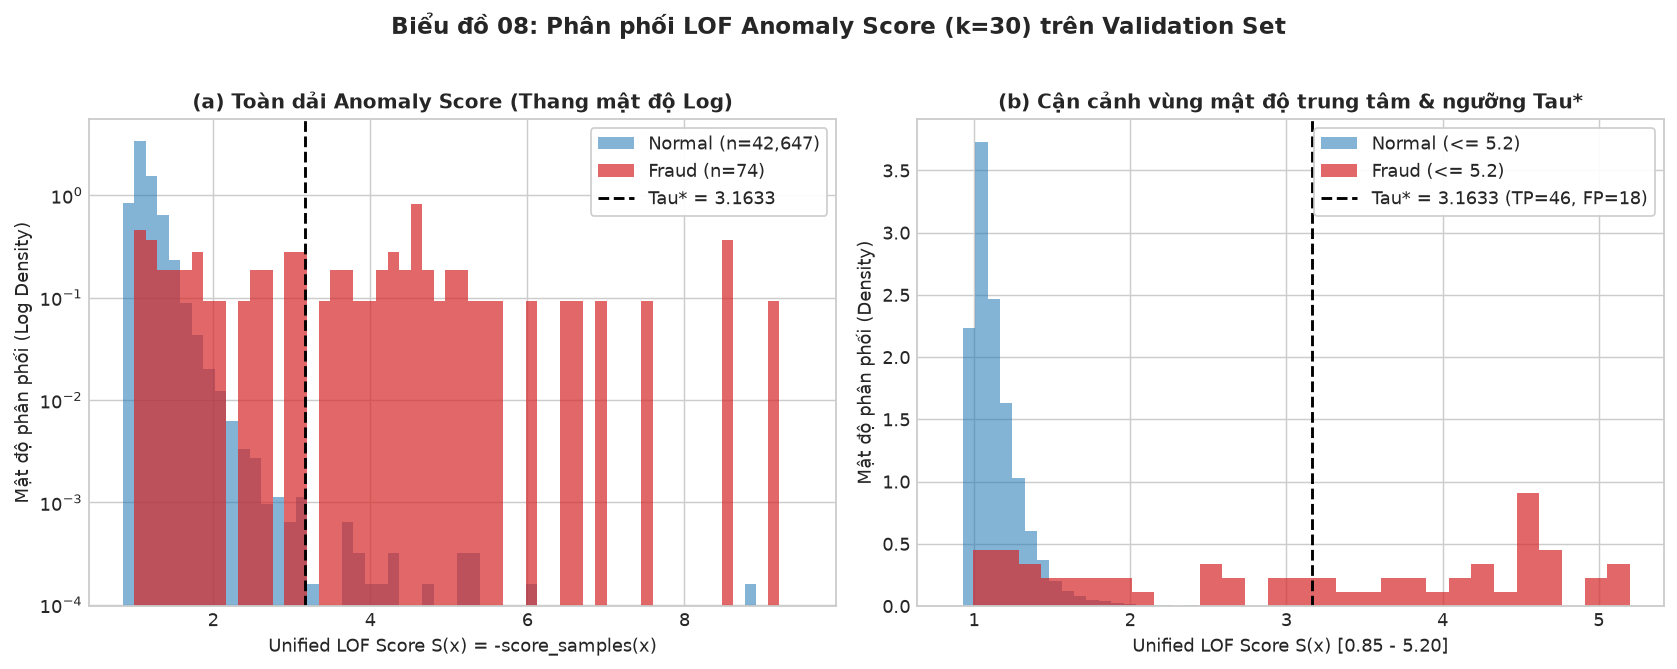

-> Đã lưu Biểu đồ 08 (300 DPI): C:\Users\Vinh Nguyen\DATAMINING\reports\figures\08_lof_score_distribution.png


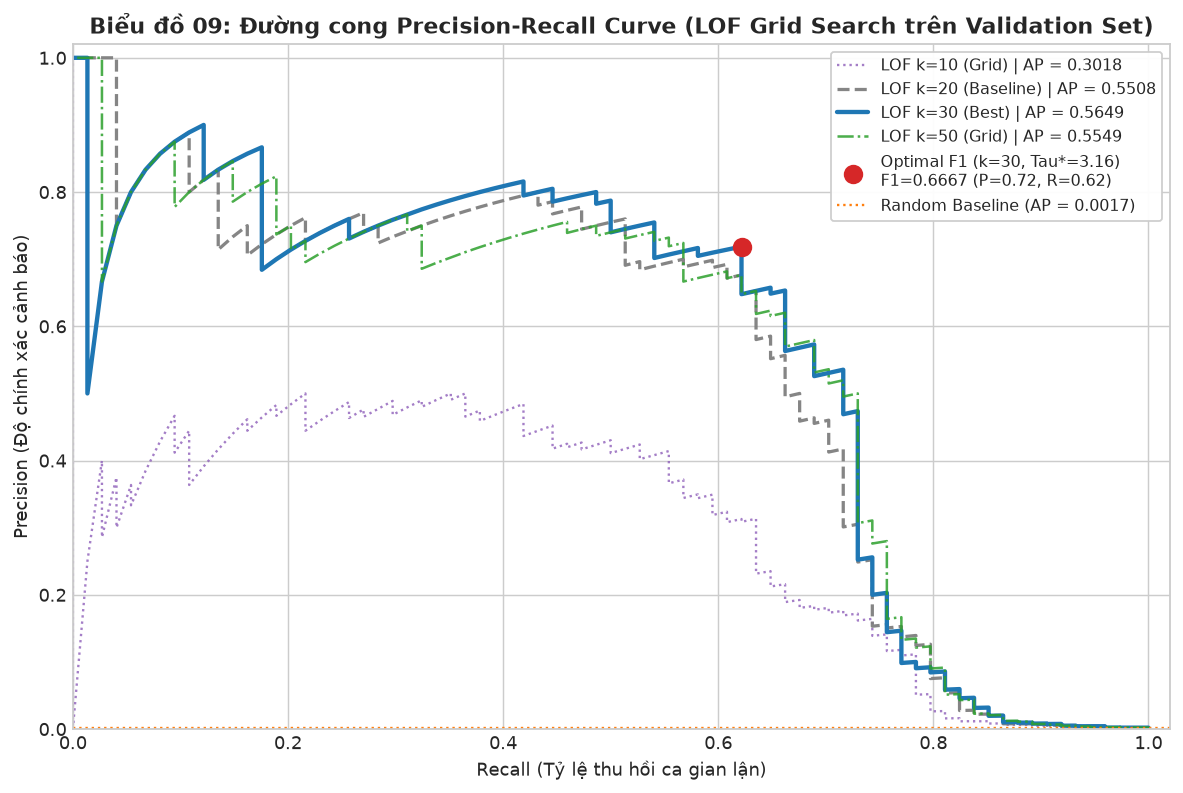

-> Đã lưu Biểu đồ 09 (300 DPI): C:\Users\Vinh Nguyen\DATAMINING\reports\figures\09_lof_pr_curve.png


In [6]:
# ==============================================================================
# BƯỚC 6: BÁO CÁO NGƯỠNG TỐI ƯU Tau*, CONFUSION MATRIX & XUẤT BIỂU ĐỒ 08–09
# ==============================================================================
# Ngưỡng cắt Tau* chỉ được tối ưu trên tập Validation để tránh làm rò rỉ thông tin Test Set;
# điểm số LOF là tỷ số mật độ cục bộ (>= 0), không diễn giải thành xác suất gian lận.
normal_scores = best_scores[y_val == 0]
fraud_scores = best_scores[y_val == 1]

print("=" * 74)
print(f"HIỆU NĂNG BEST LOF (n_neighbors={best_k}) TẠI NGƯỠNG TỐI ƯU Tau* = {best_threshold:.6f}:")
print(f"• Average Precision (AP) : {best_threshold_info['ap']:.6f}")
print(f"• Precision tại Tau*     : {best_eval['precision']:.4f} ({best_eval['precision']*100:.2f}%)")
print(f"• Recall tại Tau*        : {best_eval['recall']:.4f} ({best_eval['TP']}/{best_eval['TP'] + best_eval['FN']} ca gian lận)")
print(f"• F1-Score tại Tau*      : {best_eval['f1']:.4f}")
print(
    f"• Confusion Matrix       : TP={best_eval['TP']}, FP={best_eval['FP']}, "
    f"TN={best_eval['TN']}, FN={best_eval['FN']} "
    f"(Tổng={best_eval['TP'] + best_eval['FP'] + best_eval['TN'] + best_eval['FN']:,})"
)
print(
    f"• Phân vị điểm Normal    : Median={np.median(normal_scores):.4f}, "
    f"P99={np.percentile(normal_scores, 99):.4f}, Max={normal_scores.max():.4f}"
)
print(
    f"• Phân vị điểm Fraud     : Median={np.median(fraud_scores):.4f}, "
    f"P25={np.percentile(fraud_scores, 25):.4f}, Max={fraud_scores.max():.4f}"
)
print("=" * 74)

# ------------------------------------------------------------------------------
# Biểu đồ 08: Phân phối LOF Anomaly Score (Toàn dải Log-Y + Cận cảnh vùng ngưỡng)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bins_full = np.linspace(0.85, max(float(best_scores.max()) + 0.1, 9.5), 60)
axes[0].hist(
    normal_scores, bins=bins_full, density=True, color="#1f77b4",
    alpha=0.55, label=f"Normal (n={len(normal_scores):,})"
)
axes[0].hist(
    fraud_scores, bins=bins_full, density=True, color="#d62728",
    alpha=0.70, label=f"Fraud (n={len(fraud_scores)})"
)
axes[0].axvline(
    best_threshold, color="black", linestyle="--", linewidth=1.6,
    label=f"Tau* = {best_threshold:.4f}"
)
axes[0].set_yscale("log")
axes[0].set_title("(a) Toàn dải Anomaly Score (Thang mật độ Log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Unified LOF Score S(x) = -score_samples(x)")
axes[0].set_ylabel("Mật độ phân phối (Log Density)")
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

zoom_upper = 5.2
axes[1].hist(
    normal_scores[normal_scores <= zoom_upper], bins=55, range=(0.85, zoom_upper),
    density=True, color="#1f77b4", alpha=0.55, label="Normal (<= 5.2)"
)
axes[1].hist(
    fraud_scores[fraud_scores <= zoom_upper], bins=30, range=(0.85, zoom_upper),
    density=True, color="#d62728", alpha=0.70, label="Fraud (<= 5.2)"
)
axes[1].axvline(
    best_threshold, color="black", linestyle="--", linewidth=1.6,
    label=f"Tau* = {best_threshold:.4f} (TP={best_eval['TP']}, FP={best_eval['FP']})"
)
axes[1].set_title("(b) Cận cảnh vùng mật độ trung tâm & ngưỡng Tau*", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Unified LOF Score S(x) [0.85 - 5.20]")
axes[1].set_ylabel("Mật độ phân phối (Density)")
axes[1].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

fig.suptitle(
    f"Biểu đồ 08: Phân phối LOF Anomaly Score (k={best_k}) trên Validation Set",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
fig08_path = FIGURES_DIR / "08_lof_score_distribution.png"
fig.savefig(fig08_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu Biểu đồ 08 (300 DPI): {fig08_path}")

# ------------------------------------------------------------------------------
# Biểu đồ 09: Đường cong Precision-Recall Curve của Grid Search LOF
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.2, 6.2))

style_map = {
    10: {"color": "#9467bd", "ls": ":", "lw": 1.3, "alpha": 0.85, "tag": "Grid"},
    20: {"color": "#7f7f7f", "ls": "--", "lw": 1.8, "alpha": 0.95, "tag": "Baseline"},
    30: {"color": "#1f77b4", "ls": "-", "lw": 2.4, "alpha": 1.0, "tag": "Best"},
    50: {"color": "#2ca02c", "ls": "-.", "lw": 1.4, "alpha": 0.85, "tag": "Grid"},
}

for k in GRID_NEIGHBORS:
    th_info = experiment_results[k]["threshold_info"]
    st = style_map[k]
    ax.plot(
        th_info["recalls"],
        th_info["precisions"],
        color=st["color"],
        linestyle=st["ls"],
        linewidth=st["lw"],
        alpha=st["alpha"],
        label=f"LOF k={k} ({st['tag']}) | AP = {th_info['ap']:.4f}",
    )

ax.scatter(
    [best_eval["recall"]],
    [best_eval["precision"]],
    color="#d62728",
    s=95,
    zorder=5,
    label=(
        f"Optimal F1 (k={best_k}, Tau*={best_threshold:.2f})\n"
        f"F1={best_eval['f1']:.4f} (P={best_eval['precision']:.2f}, R={best_eval['recall']:.2f})"
    ),
)

prevalence = float(y_val.mean())
ax.axhline(
    prevalence, color="#ff7f0e", linestyle=":", linewidth=1.3,
    label=f"Random Baseline (AP = {prevalence:.4f})"
)

ax.set_title(
    "Biểu đồ 09: Đường cong Precision-Recall Curve (LOF Grid Search trên Validation Set)",
    fontsize=12, fontweight="bold"
)
ax.set_xlabel("Recall (Tỷ lệ thu hồi ca gian lận)", fontsize=10)
ax.set_ylabel("Precision (Độ chính xác cảnh báo)", fontsize=10)
ax.set_xlim([0.0, 1.02])
ax.set_ylim([0.0, 1.02])
ax.legend(
    loc="upper right",
    fontsize=8.6,
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    framealpha=0.95,
)
plt.tight_layout()

fig09_path = FIGURES_DIR / "09_lof_pr_curve.png"
fig.savefig(fig09_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu Biểu đồ 09 (300 DPI): {fig09_path}")

### Bước 7: Duplicate Sensitivity Analysis (Check A & Check B — Không Refit, Không Đổi Ngưỡng)
* **Mục đích:** Định lượng ảnh hưởng của các bản ghi Validation trùng hệt đặc trưng với tập huấn luyện do dữ liệu gốc Kaggle có $1,081$ dòng trùng lặp tự nhiên.
* **Input:** `X_train_lof` ($25,000$), `X_train` ($199,020$), `X_val` ($42,721$), `y_val`, `best_scores`, và ngưỡng cố định $\tau^*_{\text{LOF}}$.
* **Logic:** Thực hiện **2 phép kiểm chứng độc lập**:
  * **Check A (Trùng trực tiếp với mẫu con LOF):** Cô lập toàn bộ dòng Validation xuất hiện trong `X_train_lof` ($25,000$ mẫu).
  * **Check B (Trùng với toàn bộ `Train_Normal`):** Cô lập toàn bộ dòng Validation xuất hiện trong `X_train` ($199,020$ mẫu).
  * Với mỗi phép kiểm tra, xác nhận số ca Fraud trong nhóm trùng bằng `0` (bảo toàn đủ `74` ca Fraud), tính lại `AP, Precision, Recall, F1` tại đúng ngưỡng $\tau^*_{\text{LOF}}$ và báo cáo độ lệch $\Delta$ tách biệt khỏi metric chính ($42,721$ dòng).
* **Output:** Bảng đối chiếu Sensitivity Check A & Check B, ghi nhận khoảng điểm LOF của chính nhóm dòng trùng để giải thích cơ chế toán học `reach-dist`.
* **Lý do lựa chọn:** Bảo đảm minh bạch khoa học — không phóng đại hiệu năng khi đánh giá, đồng thời chứng minh mô hình LOF xử lý an toàn trường hợp khoảng cách bằng `0` nhờ chặn dưới `k-distance(o)`.
* **Rủi ro nếu làm sai:** Fit lại LOF trên tập khử trùng hoặc dùng kết quả Sensitivity để sửa ngưỡng $\tau^*$ là sai quy trình; xóa 1,081 duplicate từ gốc sẽ làm mất 19 ca Fraud quý giá.

In [7]:
# ==============================================================================
# BƯỚC 7: DUPLICATE SENSITIVITY ANALYSIS (CHECK A & CHECK B)
# ==============================================================================
def run_duplicate_sensitivity_check(
    X_reference: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    val_scores: np.ndarray,
    fixed_threshold: float,
    feature_cols: list[str],
    base_ap: float,
    base_eval: dict,
    check_label: str,
) -> dict:
    """
    Cô lập các dòng Validation trùng vector đặc trưng với tập tham chiếu và đo độ lệch metric.

    Input: Ma trận tham chiếu (X_train_lof hoặc X_train), Validation Set, điểm LOF, tau* cố định.
    Output: dict thống kê số dòng loại bỏ, dải điểm nhóm trùng, metric Dedup và Delta vs Full Val.
    Quy tắc: Không fit lại LOF và không thay đổi fixed_threshold.
    """
    # Kiểm tra duplicate leakage vì dữ liệu gốc Kaggle có các giao dịch Normal trùng chéo giữa
    # Train và Validation; cần cô lập định lượng độ lệch thay vì xóa mẫu ở gốc (làm mất 19 Fraud).
    df_ref_unique = pd.DataFrame(X_reference, columns=feature_cols).drop_duplicates()
    df_val_features = pd.DataFrame(X_val, columns=feature_cols)

    matched = df_val_features.reset_index().merge(df_ref_unique, on=feature_cols, how="inner")
    dup_val_indices = sorted(set(matched["index"].tolist()))

    assert len(dup_val_indices) > 0, f"[{check_label}] Không tìm thấy bản ghi trùng nào!"
    assert int(y_val[dup_val_indices].sum()) == 0, (
        f"[LỖI] Nhóm trùng ({check_label}) chứa nhãn Fraud!"
    )

    keep_mask = np.ones(len(X_val), dtype=bool)
    keep_mask[dup_val_indices] = False

    y_val_dedup = y_val[keep_mask]
    scores_dedup = val_scores[keep_mask]
    assert int(y_val_dedup.sum()) == 74, f"[{check_label}] Không bảo toàn đủ 74 ca Fraud!"

    ap_dedup, _, _, _ = compute_auprc(y_val_dedup, scores_dedup)
    eval_dedup = evaluate_threshold(y_val_dedup, scores_dedup, fixed_threshold)
    overlap_scores = val_scores[dup_val_indices]

    return {
        "check_label": check_label,
        "overlap_rows_removed": int(len(dup_val_indices)),
        "overlap_unique_signatures": int(
            len(df_val_features.iloc[dup_val_indices].drop_duplicates())
        ),
        "overlap_fraud_count": int(y_val[dup_val_indices].sum()),
        "overlap_score_min": float(overlap_scores.min()),
        "overlap_score_max": float(overlap_scores.max()),
        "dedup_val_samples": int(len(y_val_dedup)),
        "dedup_fraud_samples": int(y_val_dedup.sum()),
        "dedup_ap": float(ap_dedup),
        "dedup_precision": float(eval_dedup["precision"]),
        "dedup_recall": float(eval_dedup["recall"]),
        "dedup_f1": float(eval_dedup["f1"]),
        "tp": int(eval_dedup["TP"]),
        "fp": int(eval_dedup["FP"]),
        "tn": int(eval_dedup["TN"]),
        "fn": int(eval_dedup["FN"]),
        "delta_ap": float(ap_dedup - base_ap),
        "delta_precision": float(eval_dedup["precision"] - base_eval["precision"]),
        "delta_recall": float(eval_dedup["recall"] - base_eval["recall"]),
        "delta_f1": float(eval_dedup["f1"] - base_eval["f1"]),
    }


sens_check_a = run_duplicate_sensitivity_check(
    X_reference=X_train_lof,
    X_val=X_val,
    y_val=y_val,
    val_scores=best_scores,
    fixed_threshold=best_threshold,
    feature_cols=feature_names,
    base_ap=best_threshold_info["ap"],
    base_eval=best_eval,
    check_label="Check A (Overlap X_train_lof 25k)",
)

sens_check_b = run_duplicate_sensitivity_check(
    X_reference=X_train,
    X_val=X_val,
    y_val=y_val,
    val_scores=best_scores,
    fixed_threshold=best_threshold,
    feature_cols=feature_names,
    base_ap=best_threshold_info["ap"],
    base_eval=best_eval,
    check_label="Check B (Overlap Train_Normal 199k)",
)

sensitivity_table = pd.DataFrame([
    {
        "Kịch bản Kiểm chứng": "Validation Đầy đủ (Baseline Metric Chính)",
        "Mẫu": f"{len(X_val):,}",
        "Fraud": int(y_val.sum()),
        "AP": f"{best_threshold_info['ap']:.6f}",
        "Delta AP": "+0.000000",
        "Precision": f"{best_eval['precision']:.4f}",
        "Recall": f"{best_eval['recall']:.4f}",
        "F1-Score": f"{best_eval['f1']:.4f}",
        "TP / FP": f"{best_eval['TP']} / {best_eval['FP']}",
    },
    {
        "Kịch bản Kiểm chứng": f"Check A: Loại {sens_check_a['overlap_rows_removed']} dòng trùng X_train_lof",
        "Mẫu": f"{sens_check_a['dedup_val_samples']:,}",
        "Fraud": sens_check_a["dedup_fraud_samples"],
        "AP": f"{sens_check_a['dedup_ap']:.6f}",
        "Delta AP": f"{sens_check_a['delta_ap']:+.6f}",
        "Precision": f"{sens_check_a['dedup_precision']:.4f}",
        "Recall": f"{sens_check_a['dedup_recall']:.4f}",
        "F1-Score": f"{sens_check_a['dedup_f1']:.4f}",
        "TP / FP": f"{sens_check_a['tp']} / {sens_check_a['fp']}",
    },
    {
        "Kịch bản Kiểm chứng": f"Check B: Loại {sens_check_b['overlap_rows_removed']} dòng trùng Train_Normal",
        "Mẫu": f"{sens_check_b['dedup_val_samples']:,}",
        "Fraud": sens_check_b["dedup_fraud_samples"],
        "AP": f"{sens_check_b['dedup_ap']:.6f}",
        "Delta AP": f"{sens_check_b['delta_ap']:+.6f}",
        "Precision": f"{sens_check_b['dedup_precision']:.4f}",
        "Recall": f"{sens_check_b['dedup_recall']:.4f}",
        "F1-Score": f"{sens_check_b['dedup_f1']:.4f}",
        "TP / FP": f"{sens_check_b['tp']} / {sens_check_b['fp']}",
    },
])

print("=" * 102)
print("BẢNG ĐỐI CHIẾU DUPLICATE SENSITIVITY ANALYSIS (KHÔNG REFIT, GIỮ NGUYÊN Tau*):")
print("=" * 102)
print(sensitivity_table.to_string(index=False))
print("=" * 102)
print(
    f"• Check A ({sens_check_a['overlap_rows_removed']} bản ghi trùng X_train_lof): "
    f"LOF Score trong [{sens_check_a['overlap_score_min']:.4f}, {sens_check_a['overlap_score_max']:.4f}] "
    f"(< Tau*={best_threshold:.4f}) -> Delta F1 = {sens_check_a['delta_f1']:+.4f}, Delta AP = {sens_check_a['delta_ap']:+.6f}"
)
print(
    f"• Check B ({sens_check_b['overlap_rows_removed']} bản ghi trùng Train_Normal): "
    f"LOF Score trong [{sens_check_b['overlap_score_min']:.4f}, {sens_check_b['overlap_score_max']:.4f}] "
    f"(< Tau*={best_threshold:.4f}) -> Delta F1 = {sens_check_b['delta_f1']:+.4f}, Delta AP = {sens_check_b['delta_ap']:+.6f}"
)

BẢNG ĐỐI CHIẾU DUPLICATE SENSITIVITY ANALYSIS (KHÔNG REFIT, GIỮ NGUYÊN Tau*):
                      Kịch bản Kiểm chứng    Mẫu  Fraud       AP  Delta AP Precision Recall F1-Score TP / FP
Validation Đầy đủ (Baseline Metric Chính) 42,721     74 0.564948 +0.000000    0.7188 0.6216   0.6667 46 / 18
  Check A: Loại 45 dòng trùng X_train_lof 42,676     74 0.564951 +0.000003    0.7188 0.6216   0.6667 46 / 18
Check B: Loại 203 dòng trùng Train_Normal 42,518     74 0.565006 +0.000058    0.7188 0.6216   0.6667 46 / 18
• Check A (45 bản ghi trùng X_train_lof): LOF Score trong [0.9921, 1.6561] (< Tau*=3.1633) -> Delta F1 = +0.0000, Delta AP = +0.000003
• Check B (203 bản ghi trùng Train_Normal): LOF Score trong [0.9536, 2.2352] (< Tau*=3.1633) -> Delta F1 = +0.0000, Delta AP = +0.000058


### Bước 8: Đóng gói Mô hình, Kiểm thử Tái lập `joblib.load()` & Xuất Metadata / Summary
* **Mục đích:** Tuần tự hóa `best_model` ra đĩa (`models/lof_best.joblib`), nạp lại kiểm chứng khớp bit-for-bit trên Validation, và xuất đầy đủ `reports/phase4_lof_metadata.json` cùng `reports/phase4_lof_summary.md`.
* **Input:** `best_model`, `best_scores`, `df_grid_results`, `sens_check_a`, `sens_check_b`.
* **Logic:** Lưu model bằng `joblib.dump`, nạp lại bằng `joblib.load`, so sánh `score_in_batches` trên tập kiểm chứng gồm $250$ mẫu đầu + $250$ mẫu có điểm cao nhất bằng `np.array_equal` để chứng minh tái lập $100\%$; đồng thời kiểm tra một lần nữa rằng biến `X_test` và `y_test` hoàn toàn không tồn tại trong phiên làm việc.
* **Output:** `models/lof_best.joblib`, `reports/phase4_lof_metadata.json`, `reports/phase4_lof_summary.md`.
* **Lý do lựa chọn:** Bảo đảm Phase 6 (so sánh 3 mô hình & Cost Matrix) và Phase 8 (đánh giá Test) có thể nạp lại chính xác mô hình tốt nhất của Phase 4 mà không cần fit lại từ đầu.
* **Rủi ro nếu làm sai:** Ghi đè `data/processed/pipeline_metadata.json` của Phase 3 hoặc không kiểm tra `joblib.load()` có thể gây lỗi sai lệch phiên bản khi tái sử dụng sau này.

In [8]:
# ==============================================================================
# BƯỚC 8: TUẦN TỰ HÓA MÔ HÌNH, KIỂM THỬ TÁI LẬP & XUẤT METADATA / BÁO CÁO
# ==============================================================================
# 1. Lưu mô hình LOF tối ưu và kiểm thử nạp lại bit-for-bit
model_output_path = MODELS_DIR / "lof_best.joblib"
joblib.dump(best_model, model_output_path)
model_size_mb = float(model_output_path.stat().st_size / (1024.0 * 1024.0))

loaded_lof_model = joblib.load(model_output_path)

# Chọn 250 mẫu đầu + 250 mẫu có điểm LOF cao nhất (chứa các điểm biên/Fraud) để kiểm chứng nạp lại
top_250_idx = np.argsort(best_scores)[-250:]
verify_idx = np.unique(np.concatenate([np.arange(250), top_250_idx]))
scores_ram = best_scores[verify_idx]
scores_disk = score_in_batches(
    loaded_lof_model, X_val[verify_idx], batch_size=BATCH_SIZE, model_name="LOF"
)

assert np.array_equal(scores_ram, scores_disk), (
    "[LỖI TÁI LẬP] Mô hình nạp từ joblib không khớp bit-for-bit với mô hình trong RAM!"
)
assert "X_test" not in globals() and "y_test" not in globals(), "[VI PHẠM] Test Set đã xuất hiện!"

print(f"-> Đã lưu mô hình LOF tối ưu : {model_output_path} ({model_size_mb:.2f} MB)")
print(f"-> Kiểm thử joblib.load()    : PASS (khớp 100% bit-for-bit trên {len(verify_idx)} mẫu đối chiếu)")

# 2. Xuất Metadata Phase 4 đầy đủ ra reports/phase4_lof_metadata.json
phase4_metadata = {
    "project": "Credit Card Fraud Detection (Unsupervised Anomaly Detection)",
    "phase": "Phase 4 - Local Outlier Factor (LOF)",
    "random_state": RANDOM_STATE,
    "train_normal_total": int(len(X_train)),
    "lof_sample_size": int(LOF_SAMPLE_SIZE),
    "train_indices_file": "data/processed/train_indices_lof.npy",
    "num_features": len(feature_names),
    "feature_names": feature_names,
    "model_type": "sklearn.neighbors.LocalOutlierFactor",
    "fixed_parameters": {
        "novelty": True,
        "metric": "minkowski",
        "p": 2,
        "contamination": "auto",
        "n_jobs": -1,
        "scoring_batch_size": BATCH_SIZE,
    },
    "selection_rule": "max(val_ap) -> tie-break: min(total_time_sec), min(n_neighbors)",
    "baseline_metrics": {
        "n_neighbors": int(b_sum["n_neighbors"]),
        "fit_method": b_sum["fit_method"],
        "effective_metric": b_sum["effective_metric"],
        "val_ap": b_sum["val_ap"],
        "optimal_threshold": b_sum["optimal_threshold"],
        "val_precision": b_sum["val_precision"],
        "val_recall": b_sum["val_recall"],
        "val_f1": b_sum["val_f1"],
        "fit_time_sec": b_sum["fit_time_sec"],
        "score_time_sec": b_sum["score_time_sec"],
    },
    "best_hyperparameters": {
        "n_neighbors": best_k,
        "novelty": True,
        "metric": "minkowski",
        "p": 2,
        "contamination": "auto",
        "effective_metric": str(best_model.effective_metric_),
        "fit_method": str(best_model._fit_method),
    },
    "validation_metrics": {
        "val_samples": int(len(X_val)),
        "val_fraud": int(y_val.sum()),
        "best_ap": float(best_threshold_info["ap"]),
        "optimal_threshold": best_threshold,
        "precision_at_optimal_threshold": float(best_eval["precision"]),
        "recall_at_optimal_threshold": float(best_eval["recall"]),
        "f1_at_optimal_threshold": float(best_eval["f1"]),
        "confusion_matrix": {
            "TP": int(best_eval["TP"]),
            "FP": int(best_eval["FP"]),
            "TN": int(best_eval["TN"]),
            "FN": int(best_eval["FN"]),
        },
        "score_quantiles": {
            "normal_min": float(normal_scores.min()),
            "normal_median": float(np.median(normal_scores)),
            "normal_p99": float(np.percentile(normal_scores, 99)),
            "normal_max": float(normal_scores.max()),
            "fraud_min": float(fraud_scores.min()),
            "fraud_median": float(np.median(fraud_scores)),
            "fraud_p90": float(np.percentile(fraud_scores, 90)),
            "fraud_max": float(fraud_scores.max()),
        },
    },
    "grid_search_results": df_grid_results.to_dict(orient="records"),
    "duplicate_sensitivity_analysis": {
        "note": "Tách biệt khỏi metric Validation chính; không fit lại mô hình và không thay đổi tau*.",
        "check_a_overlap_lof_sample": sens_check_a,
        "check_b_overlap_full_train_normal": sens_check_b,
    },
    "serialization": {
        "model_path": "models/lof_best.joblib",
        "model_size_mb": round(model_size_mb, 4),
        "reload_bit_for_bit_verified": True,
    },
    "leakage_and_protocol_notes": {
        "test_set_loaded": False,
        "zero_leakage_claim": (
            "Không tuyên bố Zero Leakage tuyệt đối do tồn tại bản ghi Normal "
            "trùng tự nhiên giữa Train và Validation."
        ),
    },
    "environment": {
        "python_version": sys.version.split()[0],
        "scikit_learn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "psutil_version": psutil.__version__,
    },
}

metadata_path = REPORTS_DIR / "phase4_lof_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(phase4_metadata, f, indent=2, ensure_ascii=False)
print(f"-> Đã xuất metadata Phase 4   : {metadata_path}")

# 3. Xuất Báo cáo Tóm tắt Markdown Phase 4 ra reports/phase4_lof_summary.md
best_summ = best_lof_result["summary"]
grid_md_lines = [
    "| Model ID | `n_neighbors` | Fit Method | Fit (s) | Score (s) | Val AP | Optimal $F_1$ | RSS After (MB) | Heap Peak (MB) |",
    "| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |",
]
for r in grid_rows:
    grid_md_lines.append(
        f"| #{r['model_id']} | {r['n_neighbors']} | `{r['fit_method']}` | {r['fit_time_sec']:.4f} | "
        f"{r['score_time_sec']:.4f} | **{r['val_ap']:.6f}** | {r['val_f1']:.4f} | "
        f"{r['rss_after_score_mb']:.2f} | {r['tracemalloc_peak_mb']:.2f} |"
    )

summary_lines = [
    "# BÁO CÁO KẾT QUẢ PHASE 4: LOCAL OUTLIER FACTOR (LOF)",
    "",
    "* **Người phụ trách:** Nguyễn Minh Hoàng (B23DCVT173) & Nguyễn Văn Hiển Vinh (B23DCVT461)",
    rf"* **Dữ liệu huấn luyện:** Lấy mẫu không hoàn lại $N_{{\text{{LOF}}}} = {LOF_SAMPLE_SIZE:,}$ dòng từ `Train_Normal` (`RANDOM_STATE={RANDOM_STATE}`, lưu tại `data/processed/train_indices_lof.npy`).",
    rf"* **Mô hình tối ưu:** `LocalOutlierFactor(n_neighbors={best_k}, novelty=True, metric='minkowski', p=2, contamination='auto')` (`_fit_method='{best_summ['fit_method']}'`, `effective_metric_='{best_summ['effective_metric']}'`).",
    rf"* **Thời gian thực thi Best Model:** `fit_time` = {best_summ['fit_time_sec']:.4f}s | `score_time` = {best_summ['score_time_sec']:.4f}s (`batch_size={BATCH_SIZE:,}`).",
    "",
    "## 1. Kết quả Hiệu năng trên Tập Validation (42,721 mẫu, 74 Fraud)",
    rf"* **Baseline LOF (`n_neighbors=20`):** Val AP = {b_sum['val_ap']:.6f} | Best $F_1$ = {b_sum['val_f1']:.4f} ($\tau^*={b_sum['optimal_threshold']:.6f}$).",
    rf"* **Best LOF (`n_neighbors={best_k}`):** **Val AP = {best_summ['val_ap']:.6f}** ({ap_gain_abs:+.6f} so với Baseline, tương đương {ap_gain_pct:+.2f}%).",
    rf"* **Ngưỡng tối ưu $F_1$ ($\tau^*_{{\text{{LOF}}}}$):** `{best_threshold:.6f}`",
    rf"* **Precision tại $\tau^*$:** `{best_eval['precision']:.4f}` ({best_eval['precision']*100:.2f}%)",
    rf"* **Recall tại $\tau^*$:** `{best_eval['recall']:.4f}` ({best_eval['TP']}/{best_eval['TP'] + best_eval['FN']} ca gian lận)",
    rf"* **F1-Score tại $\tau^*$:** `{best_eval['f1']:.4f}`",
    rf"* **Ma trận nhầm lẫn:** `TP={best_eval['TP']}`, `FP={best_eval['FP']}`, `TN={best_eval['TN']}`, `FN={best_eval['FN']}`",
    "",
    "## 2. Kết quả Coarse Grid Search (`n_neighbors ∈ [10, 20, 30, 50]`)",
    *grid_md_lines,
    "",
    r"## 3. Duplicate Sensitivity Analysis (Không refit, giữ nguyên $\tau^*_{\text{LOF}}$)",
    rf"* **Check A — Loại {sens_check_a['overlap_rows_removed']} dòng Validation trùng trực tiếp `X_train_lof` (0 Fraud):** Còn `{sens_check_a['dedup_val_samples']:,}` mẫu (74 Fraud); AP = `{sens_check_a['dedup_ap']:.6f}` (`Delta AP = {sens_check_a['delta_ap']:+.6f}`); $F_1$ = `{sens_check_a['dedup_f1']:.4f}` (`Delta F1 = {sens_check_a['delta_f1']:+.4f}`).",
    rf"* **Check B — Loại {sens_check_b['overlap_rows_removed']} dòng Validation trùng toàn bộ `Train_Normal` (0 Fraud):** Còn `{sens_check_b['dedup_val_samples']:,}` mẫu (74 Fraud); AP = `{sens_check_b['dedup_ap']:.6f}` (`Delta AP = {sens_check_b['delta_ap']:+.6f}`); $F_1$ = `{sens_check_b['dedup_f1']:.4f}` (`Delta F1 = {sens_check_b['delta_f1']:+.4f}`).",
    rf"* **Giải thích toán học:** Do khoảng cách tiếp cận $\text{{reach-dist}}_k(p, o) = \max\{{k\text{{-dist}}(o), d(p, o)\}}$ chặn dưới bởi $k\text{{-dist}}(o) > 0$, toàn bộ bản sao chỉ nhận điểm trong dải $[{sens_check_b['overlap_score_min']:.4f}, {sens_check_b['overlap_score_max']:.4f}] < \tau^*$, không gây bất kỳ ca FP mới nào.",
    "",
    "## 4. Artifacts Bàn giao Phase 4",
    "1. `notebooks/04_local_outlier_factor.ipynb`",
    "2. `data/processed/train_indices_lof.npy`",
    rf"3. `models/lof_best.joblib` ({model_size_mb:.2f} MB — đã kiểm chứng `joblib.load()` khớp bit-for-bit)",
    "4. `reports/phase4_lof_results.csv`",
    "5. `reports/phase4_lof_metadata.json`",
    "6. `reports/phase4_lof_summary.md`",
    "7. `reports/figures/08_lof_score_distribution.png`",
    "8. `reports/figures/09_lof_pr_curve.png`",
    "",
    "*Lưu ý bảo mật:* Tập Test Set (`X_test`, `y_test`) hoàn toàn không được nạp hoặc sử dụng trong Phase 4.",
]

summary_md_path = REPORTS_DIR / "phase4_lof_summary.md"
with open(summary_md_path, "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))
print(f"-> Đã xuất báo cáo tóm tắt   : {summary_md_path}")
print("=" * 74)
print("HOÀN TẤT THỰC THI PHASE 4 — LOCAL OUTLIER FACTOR (ZERO TEST ACCESS)!")
print("=" * 74)

-> Đã lưu mô hình LOF tối ưu : C:\Users\Vinh Nguyen\DATAMINING\models\lof_best.joblib (11.83 MB)
-> Kiểm thử joblib.load()    : PASS (khớp 100% bit-for-bit trên 497 mẫu đối chiếu)
-> Đã xuất metadata Phase 4   : C:\Users\Vinh Nguyen\DATAMINING\reports\phase4_lof_metadata.json
-> Đã xuất báo cáo tóm tắt   : C:\Users\Vinh Nguyen\DATAMINING\reports\phase4_lof_summary.md
HOÀN TẤT THỰC THI PHASE 4 — LOCAL OUTLIER FACTOR (ZERO TEST ACCESS)!


### Bước 9: Kết luận Thực nghiệm Phase 4 từ Số liệu Thực
1. **Hiệu năng xếp hạng cục bộ vượt trội trên Validation:** So với Baseline $k=20$ (`Val AP = 0.550848`, `F1 = 0.6479`), cấu hình tối ưu `n_neighbors=30` đạt **`Val AP = 0.564948`**, **`Precision = 0.7188`**, **`Recall = 0.6216` (`46/74` Fraud)** và **`F1 = 0.6667`** tại ngưỡng $\tau^*_{\text{LOF}} = 3.163276$ (`TP=46, FP=18, TN=42629, FN=28`). Kết quả này cao hơn rõ rệt so với mức $k=10$ nhiễu (`AP = 0.301756`) và nhỉnh hơn $k=50$ (`AP = 0.554866`), cho thấy cấu trúc mật độ láng giềng cục bộ phản ánh rất mạnh sự tách biệt của các giao dịch bất thường trong không gian $30$ chiều đã chuẩn hóa bằng `RobustScaler`.
2. **Ổn định trước Duplicate Overlap:** Hai phép thử Sensitivity (Check A loại $45$ dòng trùng mẫu $25\text{k}$; Check B loại $203$ dòng trùng toàn bộ `Train_Normal`) giữ nguyên $TP=46, FP=18, F_1=0.6667$ (`Delta F1 = 0.0000`) và chỉ thay đổi AP không đáng kể (`+0.000003` và `+0.000058`).
3. **Tính khả thi tài nguyên:** Với $N = 25,000$ và batch scoring `5,000` dòng/lượt, mỗi cấu hình chạy hoàn tất trong khoảng **11.0–13.2 giây** (thấp hơn rất nhiều ngưỡng cảnh báo $10$ phút) với Process RSS quanh $257–286\text{ MB}$ (Peak Working Set tối đa $\approx 314.87\text{ MB}$), Python heap peak $\le 40\text{ MB}$, không tràn RAM.
4. **Giới hạn hiện tại & Bước tiếp theo:** Dù hiệu năng Validation cao hơn iForest Phase 3 (`AP = 0.103518`), LOF vẫn bỏ sót $28/74$ ca gian lận ($37.84\%$) tại ngưỡng tối ưu $F_1$, chi phí suy luận $O(N_{\text{LOF}} \cdot d)$ chậm hơn mô hình cây, và **chưa thể kết luận triển khai** trước khi đối chuẩn với One-Class SVM (Phase 5), tối ưu theo Ma trận chi phí kinh tế (Phase 6) và mở niêm phong Test Set độc lập một lần duy nhất ở Phase 8.

---

## PHẦN E: GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (DEFENSE-READY Q&A)

> **❓ Câu 1 (Thuật toán & Trực giác):** *Local Outlier Factor (LOF) là gì? LOF khác Isolation Forest ở điểm cốt lõi nào?*  
> **🎯 Trả lời:** Dạ thưa Thầy/Cô, hãy tưởng tượng hai khu dân cư: một khu phố đông đúc (nhà cách nhau $5\text{m}$) và một vùng ngoại ô thưa hơn (nhà cách nhau $50\text{m}$). Một ngôi nhà cách hàng xóm gần nhất $45\text{m}$ ở ngoại ô là hoàn toàn bình thường, nhưng cũng khoảng cách $45\text{m}$ đó nếu xuất hiện ngay cạnh khu phố đông đúc thì cực kỳ bất thường. **LOF chấm điểm dị biệt dựa trên việc so sánh độ đông đúc quanh một giao dịch so với độ đông đúc của chính các hàng xóm quanh nó**. Ngược lại, **Isolation Forest** ở Phase 3 không tính khoảng cách hay mật độ hàng xóm mà cắt ngẫu nhiên toàn cục bằng các nhát cắt song song trục tọa độ. Nhờ vậy LOF rất nhạy với những giao dịch gian lận lẩn khuất cạnh cụm người bình thường.

> **❓ Câu 2 (Công thức Reachability Distance):** *Tại sao công thức $\text{reach-dist}_k(p, o) = \max\{k\text{-dist}(o), d(p, o)\}$ lại lấy $\max$ thay vì dùng thẳng khoảng cách $d(p, o)$?*  
> **🎯 Trả lời:** Dạ có 2 lý do quan trọng: Thứ nhất, nếu nhiều điểm nằm quá gần nhau hoặc **trùng khít nhau** ($d(p, o) = 0$), việc dùng trực tiếp $d(p, o)$ sẽ làm khoảng cách trung bình tiến về $0$, kéo mật độ $\text{lrd}$ lên vô cực ($1/0$) và gây lỗi chia cho $0$. Thứ hai, việc chặn dưới bằng $k\text{-distance}(o)$ đóng vai trò như một bộ lọc làm mượt cục bộ, giúp điểm số LOF ổn định hơn, ít bị giật mạnh vì sai số nhỏ của một vài hàng xóm quá sát.

> **❓ Câu 3 (Diễn giải công thức $\text{lrd}$ và LOF score):** *Nhìn vào công thức $\text{LOF}_k(p)$, làm sao biết con số nào là bình thường, con số nào là bất thường?*  
> **🎯 Trả lời:** Dạ công thức $\text{LOF}_k(p)$ thực chất là tỷ số giữa **mật độ trung bình của $k$ hàng xóm** chia cho **mật độ tại điểm $p$**.  
> * Nếu $p$ ở trong vùng có độ đông đúc tương đương hàng xóm thì tử số $\approx$ mẫu số $\implies \text{LOF} \approx 1$ (bình thường; trên Validation của nhóm, trung vị Normal là `1.0969`).  
> * Nếu $p$ bị cô lập ở vùng loãng hơn hẳn hàng xóm thì mật độ $\text{lrd}(p)$ nhỏ, kéo tỷ số tăng vọt lên $\gg 1$ (trên Validation, nhóm Fraud có trung vị lên tới `3.9375`, có điểm tới `9.1253`).

> **❓ Câu 4 (Tham số `novelty=True` & API):** *Vì sao bắt buộc phải đặt `novelty=True`? Không dùng `negative_outlier_factor_` để chấm điểm Validation được sao?*  
> **🎯 Trả lời:** Dạ trong `scikit-learn`, mặc định `novelty=False` chỉ dùng để phát hiện ngoại lai bên trong chính tập dữ liệu đang fit (`fit_predict`), và giá trị `negative_outlier_factor_` chỉ được tính cho $25,000$ mẫu huấn luyện `X_train_lof` chứ không liên quan tới tập Validation. Khi bật `novelty=True`, mô hình giữ nguyên cấu trúc tham chiếu `Train_Normal` đã học và kích hoạt hàm `.score_samples(X_val)` để chấm điểm các giao dịch **hoàn toàn mới chưa từng gặp** trong Validation (và sau này là Test), bảo đảm đúng bản chất Novelty Detection và không làm ô nhiễm tập tham chiếu.

> **❓ Câu 5 (Tham số `n_neighbors` & Kết quả Grid Search):** *Tham số `n_neighbors` ($k$) có ý nghĩa gì và thực nghiệm $k \in [10, 20, 30, 50]$ cho thấy điều gì?*  
> **🎯 Trả lời:** Dạ $k$ là số lượng giao dịch láng giềng dùng để ước lượng mật độ cục bộ. Thực nghiệm trên cùng $25,000$ mẫu Train và $42,721$ mẫu Validation cho thấy:  
> * Với $k=10$ (quá nhỏ): ước lượng mật độ dễ bị nhiễu bởi vài giao dịch bình thường lẻ tẻ nên `Val AP` rớt xuống chỉ còn `0.3018`.  
> * Khi tăng lên $k=20$ (Baseline): `Val AP` nhảy vọt lên `0.5508`.  
> * Tại $k=30$ (tối ưu): đạt cân bằng tốt nhất giữa độ mượt thống kê và độ nhạy cục bộ với **`Val AP = 0.564948`**, `F1 = 0.6667`.  
> * Khi lên $k=50$: vùng láng giềng mở rộng quá mức khiến cấu trúc cục bộ bị làm mượt hơn, `Val AP` giảm nhẹ về `0.5549` và `tracemalloc` heap peak tăng gấp gần $5$ lần so với $k=10$ (`40.0 MB` vs `8.5 MB`). Vì vậy $k=30$ được chọn một cách khách quan.

> **❓ Câu 6 (Lấy mẫu $25,000$ & `train_indices_lof.npy`):** *Vì sao chỉ lấy $25,000$ dòng từ $199,020$ dòng `Train_Normal` mà không fit hết? File `train_indices_lof.npy` để làm gì?*  
> **🎯 Trả lời:** Dạ vì khi tìm $k$ láng giềng gần nhất trong không gian $30$ chiều, hiện tượng **Lời nguyền số chiều (Curse of Dimensionality)** khiến các cây chia không gian như `kd_tree`/`ball_tree` không còn tăng tốc hiệu quả, nên `scikit-learn` tự chọn chế độ `algorithm='brute'` với độ phức tạp $O(N^2 \cdot d)$. Nếu giữ cả $199,020$ dòng, số phép tính khoảng cách tăng gấp $(199/25)^2 \approx 63$ lần, rất dễ quá tải thời gian hoặc RAM trên laptop sinh viên. Với $N = 25,000$ cố định bằng `RandomState(42)` (không hoàn lại) và lưu cứng mảng chỉ số vào `train_indices_lof.npy`, mọi cấu hình Grid Search đều chạy gọn trong ~11–13 giây trên **cùng một tập tham chiếu** và tái lập lại 100% giữa hai thành viên nhóm.

> **❓ Câu 7 (Vai trò chuẩn hóa `RobustScaler`):** *Nếu quên chuẩn hóa `Amount` và `Time` ở Phase 2 thì LOF sẽ bị hỏng như thế nào?*  
> **🎯 Trả lời:** Dạ cực kỳ nghiêm trọng ạ! Vì LOF dùng khoảng cách Euclidean $p=2$ cộng tổng bình phương sai khác trên cả $30$ chiều. Nếu chưa scale, biến `Time` chạy từ $0$ đến $172,792$ giây và `Amount` lên tới $25,691$ USD — gấp hàng nghìn lần biên độ $[-3, +3]$ của $28$ biến PCA `V1–V28`. Lúc đó khoảng cách Euclidean sẽ bị thống trị hoàn toàn bởi hai biến `Time` và `Amount`, làm vô hiệu hóa mọi thông tin ẩn chứa trong `V1–V28`. Nhờ `RobustScaler` (fit chỉ trên `Train_Normal`), cả $30$ chiều được đưa về thang đo đồng đều hơn mà vẫn kháng được các khoản tiền cực đại.

> **❓ Câu 8 (Code đảo dấu & Hiểu nhầm xác suất):** *Trong `src/models.py`, vì sao lại trả về `-model.score_samples(X)`? Điểm LOF = 3.16 có phải là xác suất gian lận không?*  
> **🎯 Trả lời:** Dạ:  
> 1. Phải đảo dấu `-score_samples(X)` vì `scikit-learn` trả về số âm (ví dụ `-3.16` là rất dị biệt, `-1.05` là bình thường), trong khi các hàm chuẩn như `average_precision_score` và `precision_recall_curve` quy ước **giá trị càng lớn càng thuộc lớp Fraud (class 1)**. Nếu quên đảo dấu, mô hình sẽ xếp các điểm bình thường lên đầu bảng cảnh báo!  
> 2. Điểm số này **tuyệt đối không phải xác suất**, vì $\text{LOF} \ge 0$ không nằm trong đoạn $[0, 1]$ mà là tỷ số mật độ cục bộ. Ngoài ra, **Outlier không đồng nghĩa hoàn toàn với Fraud**: ví dụ tại ngưỡng $\tau^* = 3.1633$, vẫn có $18$ giao dịch bình thường có hành vi lạ rơi vào nhóm False Positive.

> **❓ Câu 9 (Batch Scoring & Tính nhất quán):** *Tại sao khi chấm điểm Validation (42,721 dòng) code lại chia thành các batch 5,000 dòng? Làm sao biết chia batch không làm sai số?*  
> **🎯 Trả lời:** Dạ trong chế độ `novelty=True`, `LOF.score_samples(X_val)` tính khoảng cách từ mỗi giao dịch Validation tới **tập tham chiếu cố định $25,000$ điểm `X_train_lof`**, hoàn toàn **không phụ thuộc vào các điểm Validation khác cùng batch**. Vì vậy chia từng lô $5,000$ dòng giúp giữ kích thước ma trận khoảng cách trung gian ở mức $5,000 \times 25,000$ thay vì $42,721 \times 25,000$, giảm đỉnh RAM đột biến mà vẫn giữ nguyên 100% giá trị điểm số — điều này đã được kiểm chứng bằng lệnh `assert np.allclose(..., atol=1e-12)` khớp tuyệt đối với chấm điểm nguyên khối trên $500$ mẫu kiểm thử.

> **❓ Câu 10 (Runtime & Bộ nhớ `psutil` vs `tracemalloc`):** *Tại sao `tracemalloc` báo đỉnh heap chỉ 8.5–40 MB trong khi `psutil` RSS lại vào khoảng 257–286 MB?*  
> **🎯 Trả lời:** Dạ vì `tracemalloc` chỉ theo dõi phần bộ nhớ do **Python Memory Manager** quản lý (các object Python thuần), không nhìn thấy phần lớn vùng nhớ native C / BLAS / joblib cấp phát ở tầng hệ điều hành và nền runtime Python đã nạp sẵn khi tính khoảng cách Euclidean song song (`n_jobs=-1`). Do đó nhóm báo cáo song song **Process RSS** (snapshot trước/sau fit/score, delta RSS `+1.45` đến `+8.54 MB`, `peak_wset` lên tới `~315 MB` trên Windows qua `psutil`) và **Python heap peak** (`8.5–40.0 MB` qua `tracemalloc`), đồng thời **không gọi nhầm RSS delta là Peak memory**.

> **❓ Câu 11 (Duplicate Sensitivity Check A & Check B):** *Tập Validation có $45$ dòng trùng với $25\text{k}$ mẫu con LOF và $203$ dòng trùng với toàn bộ `Train_Normal`. Khi loại bỏ các dòng trùng đó, tại sao kết quả AP gần như không đổi?*  
> **🎯 Trả lời:** Dạ đây là một phát hiện toán học rất đẹp trong thực nghiệm Phase 4! Toàn bộ $45$ dòng (Check A) và $203$ dòng (Check B) trùng lặp đều là nhãn **Normal (0 Fraud)**. Hơn nữa, dù có khoảng cách bằng $0$ tới chính nó trong `X_train_lof`, nhờ chặn dưới `k-distance(o) > 0` của công thức `reach-dist`, điểm LOF của các bản sao này chỉ rơi vào đoạn `0.9536 – 2.2352`, hoàn toàn nằm dưới ngưỡng $\tau^*_{\text{LOF}} = 3.1633$. Do đó chúng không tạo ra bất kỳ ca báo động nhầm (FP) nào: `TP=46, FP=18, F1=0.6667` **giữ nguyên bất biến (`Delta F1 = 0.0000`)**, còn AP chỉ dịch vi mô `+0.000003` (Check A) và `+0.000058` (Check B). Tuy nhiên, để giữ so sánh công bằng với Phase 3 và Phase 5, bảng điểm chính thức vẫn thống nhất đánh giá trên đúng $42,721$ dòng Validation gốc.

> **❓ Câu 12 (Hạn chế & Ý nghĩa kết quả thực nghiệm):** *LOF đạt Validation AP = 0.5649 (cao gấp ~5.46 lần Isolation Forest 0.1035), vậy nhóm có thể chốt luôn LOF làm mô hình triển khai thực tế không?*  
> **🎯 Trả lời:** Dạ **chưa thể chốt ngay ạ**, vì 4 lý do khoa học:  
> 1. Dù AP và F1 tăng vượt bậc, mô hình LOF tốt nhất vẫn còn **bỏ lọt $28/74$ giao dịch gian lận ($37.84\%$)** — mức Recall `62.16%` vẫn cần phân tích tiếp bằng Cost Matrix ở Phase 6 xem có đạt mục tiêu đánh đổi chi phí ngân hàng hay không.  
> 2. Chi phí dự đoán mỗi giao dịch mới của LOF đòi hỏi đối chiếu khoảng cách $O(N_{\text{LOF}} \cdot d)$ tới $25,000$ mẫu (`9.26 giây` chấm `42,721` mẫu cho `k=30`), chậm hơn khoảng $19$ lần so với `0.49 giây` của iForest, và dung lượng file model (`11.83 MB`) lớn hơn iForest (`2.41 MB`).  
> 3. Cần hoàn thành Phase 5 (One-Class SVM kernel RBF) và Phase 6 (so sánh tổng hợp + ngưỡng theo Cost Matrix) trên cùng tập Validation.  
> 4. Tập Test ($42,722$ mẫu, $74$ Fraud) vẫn đang được niêm phong cho tới Phase 8 để thẩm định khách quan năng lực tổng quát hóa cuối cùng.